# Regime-Conditioned CVaR-QAOA for Nifty 50 Portfolio Selection
**A transparent, end-to-end hybrid quantum-classical study (Phases 0-7 + simulation reports + live dashboard).**

Pipeline: *market-regime inference* (classical Gaussian HMM, then a quantum data re-uploading VQC) -> *posterior-blended cost* -> *pick exactly K of N stocks* with **CVaR-QAOA (Dicke start + XY mixer)** vs penalty-QAOA, brute force and simulated annealing -> *walk-forward backtest* on real Nifty 50 data (2018-01 to 2026-10).

> **No quantum-advantage claim is made.** At N = 11 the exact answer is found by brute force in milliseconds. The goal is an honest, reproducible benchmark of what the quantum components do and do not add.

### How to use this notebook
1. **Run All** (Colab or local Jupyter). Everything is self-contained: the Nifty 50 price snapshot is bundled inside the notebook, no API keys, no network needed.
2. Set `MODE` in the *Configuration* cell: `FAST` (~5-8 min, smaller experiments) or `FULL` (~25-40 min, the numbers quoted in the reports). `DATA_MODE="live"` refreshes prices from Yahoo Finance.
3. Jump to **Section 11 (Live dashboard)** to see *today's picks*, the current regime and the strategy comparison. Section 12 writes `results/Simulation_Report.pdf`, tables, figures and `dashboard.html`.

| Research question | Where |
|---|---|
| RQ1 quantum regime model (VQC) vs Gaussian HMM | Section 7 |
| RQ2 XY + Dicke + CVaR vs penalty QAOA | Section 5 |
| RQ3 regime-keyed warm starts (with controls) | Section 6 |
| RQ4 noise / hardware | Section 10 (shot-noise, simulation only) + final report. Real hardware is out of scope here |


## 0. Setup

In [1]:
# Installs only what is missing (works on Colab and locally). Versions used for the reported results are in requirements.txt.
import importlib.util, subprocess, sys
_pkgs = {"qiskit": "qiskit>=2.0,<3", "hmmlearn": "hmmlearn>=0.3", "statsmodels": "statsmodels", "plotly": "plotly", "ipywidgets": "ipywidgets", "reportlab": "reportlab", "yfinance": "yfinance"}
_missing = [v for k, v in _pkgs.items() if importlib.util.find_spec(k) is None]
for _p in _missing:                       # yfinance is only needed for DATA_MODE="live"; a failed optional install is not fatal
    try: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _p])
    except Exception as _e: print(f"warning: could not install {_p} ({_e})")
import qiskit, numpy, scipy, pandas, hmmlearn
print({m.__name__: m.__version__ for m in (qiskit, numpy, scipy, pandas, hmmlearn)})   # record these for reproducibility
# Optional: keep results across Colab sessions
# from google.colab import drive; drive.mount('/content/drive'); import os; os.chdir('/content/drive/MyDrive/quantum_portfolio')


{'qiskit': '2.5.2', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.2', 'hmmlearn': '0.3.3'}


In [2]:
#@title Configuration { display-mode: "form" }
MODE      = "FULL"       #@param ["FAST", "FULL"]
DATA_MODE = "snapshot"   #@param ["snapshot", "live"]
SEED = 42
import random, os, math, time, numpy as np
os.makedirs("results/figs", exist_ok=True)
import logging, warnings; logging.getLogger("hmmlearn.base").setLevel(logging.ERROR); warnings.filterwarnings("ignore", category=FutureWarning)
random.seed(SEED); np.random.seed(SEED)
_PRESETS = {
  "FAST": dict(refit=126, rebal=42, rq2_inst=3, rq2_seeds=1, rq2_depths=(1, 2), lib_restarts=2,
               specs=("cold1", "blend", "prev"), controls=("shuffled",), vqc_rv=False, boot=500,
               sens=False, scale_Ns=(8, 10, 12), shot_inst=2),
  "FULL": dict(refit=63, rebal=21, rq2_inst=8, rq2_seeds=3, rq2_depths=(1, 2, 3), lib_restarts=4,
               specs=("cold1", "cold3", "dominant", "blend", "prev"), controls=("shuffled", "pooled"), vqc_rv=True, boot=2000,
               sens=True, scale_Ns=(8, 10, 12, 14, 16, 18), shot_inst=4),
}
CFG = _PRESETS[MODE]
print(f"MODE={MODE}  DATA_MODE={DATA_MODE}\n", CFG)


MODE=FULL  DATA_MODE=snapshot
 {'refit': 63, 'rebal': 21, 'rq2_inst': 8, 'rq2_seeds': 3, 'rq2_depths': (1, 2, 3), 'lib_restarts': 4, 'specs': ('cold1', 'cold3', 'dominant', 'blend', 'prev'), 'controls': ('shuffled', 'pooled'), 'vqc_rv': True, 'boot': 2000, 'sens': True, 'scale_Ns': (8, 10, 12, 14, 16, 18), 'shot_inst': 4}


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qiskit

# Statistics and Hidden Markov Models
import scipy.stats as stats
import statsmodels.api as sm
from hmmlearn import hmm

print("Libraries successfully imported:")
print(f"- numpy: {np.__version__}")
print(f"- pandas: {pd.__version__}")
print(f"- qiskit: {qiskit.__version__}")

Libraries successfully imported:
- numpy: 2.4.4
- pandas: 3.0.2
- qiskit: 2.5.2


## 1. Phase 1 - Data, frozen universe, features, walk-forward splitter, leakage tests (your code)

In [4]:
#@title Bundled Nifty 50 price snapshot (2018-01-01 to 2026-10-09, adjusted close, 18 tickers) { display-mode: "form" }
_SNAPSHOT_B64 = "..."


In [5]:
import os
import numpy as np
import pandas as pd

# =====================================================================
# 1. CONFIGURATION & CACHING
# =====================================================================
CACHE_FILE = "nifty50_prices.csv"

# A selection of Nifty 50 constituent tickers (with .NS suffix for Yahoo Finance)
NIFTY50_TICKERS = [
    "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "ICICIBANK.NS", "INFY.NS",
    "HINDUNILVR.NS", "ITC.NS", "LT.NS", "SBIN.NS", "BHARTIARTL.NS",
    "KOTAKBANK.NS", "AXISBANK.NS", "BAJFINANCE.NS", "M&M.NS", "MARUTI.NS"
]

# Frozen selected universe (11 names) picked based on sector diversity and liquidity
SELECTED_UNIVERSE = [
    "RELIANCE.NS",    # Energy
    "TCS.NS",         # IT
    "HDFCBANK.NS",    # Financials
    "HINDUNILVR.NS",  # FMCG
    "LT.NS",          # Construction / Capital Goods
    "SBIN.NS",        # PSU Bank
    "BHARTIARTL.NS",  # Telecom
    "M&M.NS",         # Auto
    "SUNPHARMA.NS",   # Pharma
    "ULTRACEMCO.NS",  # Materials / Cement
    "POWERGRID.NS"    # Utilities
]

import base64, gzip, io
def _snapshot_df():
    raw = gzip.decompress(base64.b64decode(_SNAPSHOT_B64)).decode()
    return pd.read_csv(io.StringIO(raw), index_col=0, parse_dates=True)

def load_data(start_date="2018-01-01", end_date=None):
    """DATA_MODE='snapshot' -> bundled adjusted-close prices (reproducible, no network).
       DATA_MODE='live'     -> Yahoo Finance refresh through today (falls back to the snapshot if offline)."""
    if DATA_MODE == "live":
        try:
            import yfinance as yf
            tick = sorted(set(NIFTY50_TICKERS + SELECTED_UNIVERSE)) + ["^NSEI"]
            raw = yf.download(tick, start=start_date, end=end_date, auto_adjust=True, progress=False)
            df = (raw["Adj Close"] if "Adj Close" in raw else raw["Close"]).dropna(how="all")
            if len(df) < 1000: raise RuntimeError("download too short")
            df.to_csv(CACHE_FILE); print(f"Live data: {df.index.min().date()} .. {df.index.max().date()}"); return df
        except Exception as e:
            print(f"live download failed ({e}); using the bundled snapshot")
    df = _snapshot_df()
    if not os.path.exists(CACHE_FILE): df.to_csv(CACHE_FILE)
    return df

# =====================================================================
# 2. PRE-SCREENING RULE & FILTERING
# =====================================================================
def screen_universe(df, target_count=11):
    """
    Documents and executes the pre-screening rule:
    1. Filter out tickers with more than 5% missing values.
    2. Select the top diversified tickers representing different sectors.
    """
    missing_ratios = df.isnull().mean()
    valid_tickers = missing_ratios[missing_ratios < 0.05].index.tolist()

    # Keep only those in our predefined frozen list
    final_tickers = [t for t in SELECTED_UNIVERSE if t in valid_tickers]
    return df[final_tickers]

# =====================================================================
# 3. FEATURE ENGINEERING
# =====================================================================
def compute_features(df, vol_window=20, mom_window=20):
    """
    Computes log returns, rolling volatility, and momentum.
    Ensures no future data leakage by strictly using shift() and rolling() parameters.
    """
    features = {}

    for col in df.columns:
        prices = df[col]
        # Log Returns (strictly historical, relying on past 1-day step)
        log_ret = np.log(prices / prices.shift(1))

        # Rolling Volatility (historical backward-looking window)
        # closed='left' parameter prevents including the current day's price in the window calculation
        # but to keep it simple, we compute standard rolling and shift by 1 to make it strictly predictive/historical
        roll_vol = log_ret.rolling(window=vol_window).std().shift(1)

        # Momentum (simple past return over the mom_window, shifted to prevent leak)
        momentum = log_ret.rolling(window=mom_window).sum().shift(1)

        features[f"{col}_log_return"] = log_ret
        features[f"{col}_volatility"] = roll_vol
        features[f"{col}_momentum"] = momentum

    features_df = pd.DataFrame(features, index=df.index)
    return features_df

# =====================================================================
# 4. WALK-FORWARD SPLITTER
# =====================================================================
class WalkForwardSplitter:
    def __init__(self, train_size=252, test_size=63, step_size=63, expanding=False):
        self.train_size = train_size
        self.test_size = test_size
        self.step_size = step_size
        self.expanding = expanding

    def split(self, df):
        """
        Generates (train_indices, test_indices) tuples.
        """
        n_samples = len(df)
        start = 0

        while True:
            train_start = 0 if self.expanding else start
            train_end = start + self.train_size
            test_end = train_end + self.test_size

            if test_end > n_samples:
                break

            yield list(range(train_start, train_end)), list(range(train_end, test_end))
            start += self.step_size

# =====================================================================
# 5. UNIT TESTS & LEAKAGE CHECKS
# =====================================================================
def run_unit_tests():
    print("\n--- Running Unit Tests ---")

    # 1. Load data
    df_raw = load_data()
    df_screened = screen_universe(df_raw)

    # Test 1: Check universe size
    assert len(df_screened.columns) == 11, f"Expected 11 names, got {len(df_screened.columns)}"
    print("Test 1 Passed: Selected exactly 11 tickers.")

    # 2. Compute features
    df_features = compute_features(df_screened)

    # Test 2: Alignment & NaNs check (excluding initial warm-up rows)
    warmup_period = 21
    test_slice = df_features.iloc[warmup_period:]
    assert not test_slice.isnull().any().any(), "Detected unexpected NaNs after warm-up period!"
    print("Test 2 Passed: No NaNs present after the expected warm-up period.")

    # Test 3: Walk-Forward alignment
    splitter = WalkForwardSplitter(train_size=252, test_size=63, step_size=63, expanding=False)
    splits = list(splitter.split(df_screened))
    assert len(splits) > 0, "No splits were generated."

    first_train, first_test = splits[0]
    assert max(first_train) < min(first_test), "Overlapping train and test indices found!"
    print("Test 3 Passed: Splitter ensures strict temporal alignment without overlap.")

    # Test 4: Explicit look-ahead leakage check
    # Modify historical data and check that future features do not change
    original_features = compute_features(df_screened).copy()
    modified_df = df_screened.copy()

    # Perturb a value in the future (e.g. index 100)
    target_idx = 100
    col_to_test = df_screened.columns[0]
    modified_df.iloc[target_idx, modified_df.columns.get_loc(col_to_test)] += 10.0

    modified_features = compute_features(modified_df)

    # Check that any feature before target_idx is absolutely unchanged
    for col in modified_features.columns:
        pd.testing.assert_series_equal(
            original_features[col].iloc[:target_idx],
            modified_features[col].iloc[:target_idx],
            obj=f"Feature {col} before index {target_idx} is affected by future changes (Look-ahead Leakage!)"
        )
    print("Test 4 Passed: No look-ahead leakage detected. Future changes do not affect past features.")
    print("All Phase 1 tests passed successfully!")

# Run the pipeline and unit tests
run_unit_tests()


--- Running Unit Tests ---


Test 1 Passed: Selected exactly 11 tickers.
Test 2 Passed: No NaNs present after the expected warm-up period.
Test 3 Passed: Splitter ensures strict temporal alignment without overlap.
Test 4 Passed: No look-ahead leakage detected. Future changes do not affect past features.
All Phase 1 tests passed successfully!


## 2a. Market regime HMM, full-sample (your code - used for visualisation and as a smoke test only; the backtests below refit walk-forward)

In [6]:
import numpy as np
import pandas as pd
from hmmlearn import hmm

# =====================================================================
# 1. LOAD DATA & COMPUTE FEATURES FOR ALL SELECTED STOCKS
# =====================================================================
raw_prices = load_data()
screened_prices = screen_universe(raw_prices)
features_df = compute_features(screened_prices)

# =====================================================================
# 2. CREATE A MARKET PROXY & FIT THE 3-STATE MARKET HMM
# =====================================================================
# Calculate market return as the equal-weighted average of the selected constituents' log returns
log_return_cols = [col for col in features_df.columns if col.endswith("_log_return")]
market_log_returns = features_df[log_return_cols].mean(axis=1)

# Combine market return with time index and clean NaNs
market_df = pd.DataFrame({"Market_Log_Return": market_log_returns}).dropna()

# Prepare input for HMM
X_market = market_df[["Market_Log_Return"]].values

# Fit 3-state Gaussian HMM representing overall market conditions
market_hmm = hmm.GaussianHMM(n_components=3, covariance_type="diag", random_state=42, n_iter=100)
market_hmm.fit(X_market)

market_states = market_hmm.predict(X_market)
market_posterior_probs = market_hmm.predict_proba(X_market)

# =====================================================================
# 3. SORT REGIMES BY MARKET VOLATILITY (0 = Low, 1 = Med, 2 = High)
# =====================================================================
state_variances = np.array([np.var(X_market[market_states == i]) for i in range(3)])
sorted_indices = np.argsort(state_variances)
state_map = {old_idx: new_idx for new_idx, old_idx in enumerate(sorted_indices)}

# Apply sorted mapping to market states and posterior probabilities
sorted_market_states = np.vectorize(state_map.get)(market_states)
sorted_market_probs = market_posterior_probs[:, sorted_indices]

# Add market metrics back to a common market dataframe
market_results = pd.DataFrame(index=market_df.index)
market_results["Market_Regime"] = sorted_market_states
market_results["Prob_Market_Regime_0_Low_Vol"] = sorted_market_probs[:, 0]
market_results["Prob_Market_Regime_1_Med_Vol"] = sorted_market_probs[:, 1]
market_results["Prob_Market_Regime_2_High_Vol"] = sorted_market_probs[:, 2]

# =====================================================================
# 4. GENERATE INDIVIDUAL DATA_FRAMES FOR ALL SELECTED STOCKS
# =====================================================================
stock_dfs = {}
for stock in SELECTED_UNIVERSE:
    # Extract individual indicators
    single_stock_df = pd.DataFrame({
        "Price": screened_prices[stock],
        "Log_Return": features_df[f"{stock}_log_return"],
        "Volatility": features_df[f"{stock}_volatility"],
        "Momentum": features_df[f"{stock}_momentum"]
    })

    # Align with the market regime and probabilities
    aligned_stock_df = single_stock_df.join(market_results, how="inner")
    stock_dfs[stock] = aligned_stock_df

# =====================================================================
# 5. DISPLAY SAMPLE RESULTS
# =====================================================================
print("=== MARKET REGIME SUMMARY STATS ===")
for regime_idx in range(3):
    count = (sorted_market_states == regime_idx).sum()
    mean_ret = X_market[sorted_market_states == regime_idx].mean() * 100
    std_ret = X_market[sorted_market_states == regime_idx].std() * 100
    name = ['Low Vol', 'Medium Vol', 'High Vol'][regime_idx]
    print(f"Market Regime {regime_idx} ({name}): Count = {count}, Mean Return = {mean_ret:.4f}%, Volatility = {std_ret:.4f}%")

test_stock = SELECTED_UNIVERSE[0]
print(f"\n=== ALIGNED DATAFRAME SAMPLE FOR {test_stock} ===")
print(stock_dfs[test_stock].head(10).to_string())

=== MARKET REGIME SUMMARY STATS ===
Market Regime 0 (Low Vol): Count = 1051, Mean Return = 0.0198%, Volatility = 0.8213%
Market Regime 1 (Medium Vol): Count = 1054, Mean Return = 0.0938%, Volatility = 0.8398%
Market Regime 2 (High Vol): Count = 61, Mean Return = -0.2635%, Volatility = 3.7408%

=== ALIGNED DATAFRAME SAMPLE FOR RELIANCE.NS ===
               Price  Log_Return  Volatility  Momentum  Market_Regime  Prob_Market_Regime_0_Low_Vol  Prob_Market_Regime_1_Med_Vol  Prob_Market_Regime_2_High_Vol
Date                                                                                                                                                            
2018-01-02  400.6309    0.001538         NaN       NaN              1                      0.038495                      0.961505                   3.836633e-11
2018-01-03  402.2358    0.003998         NaN       NaN              0                      0.957391                      0.041656                   9.528327e-04
2018-01-04  

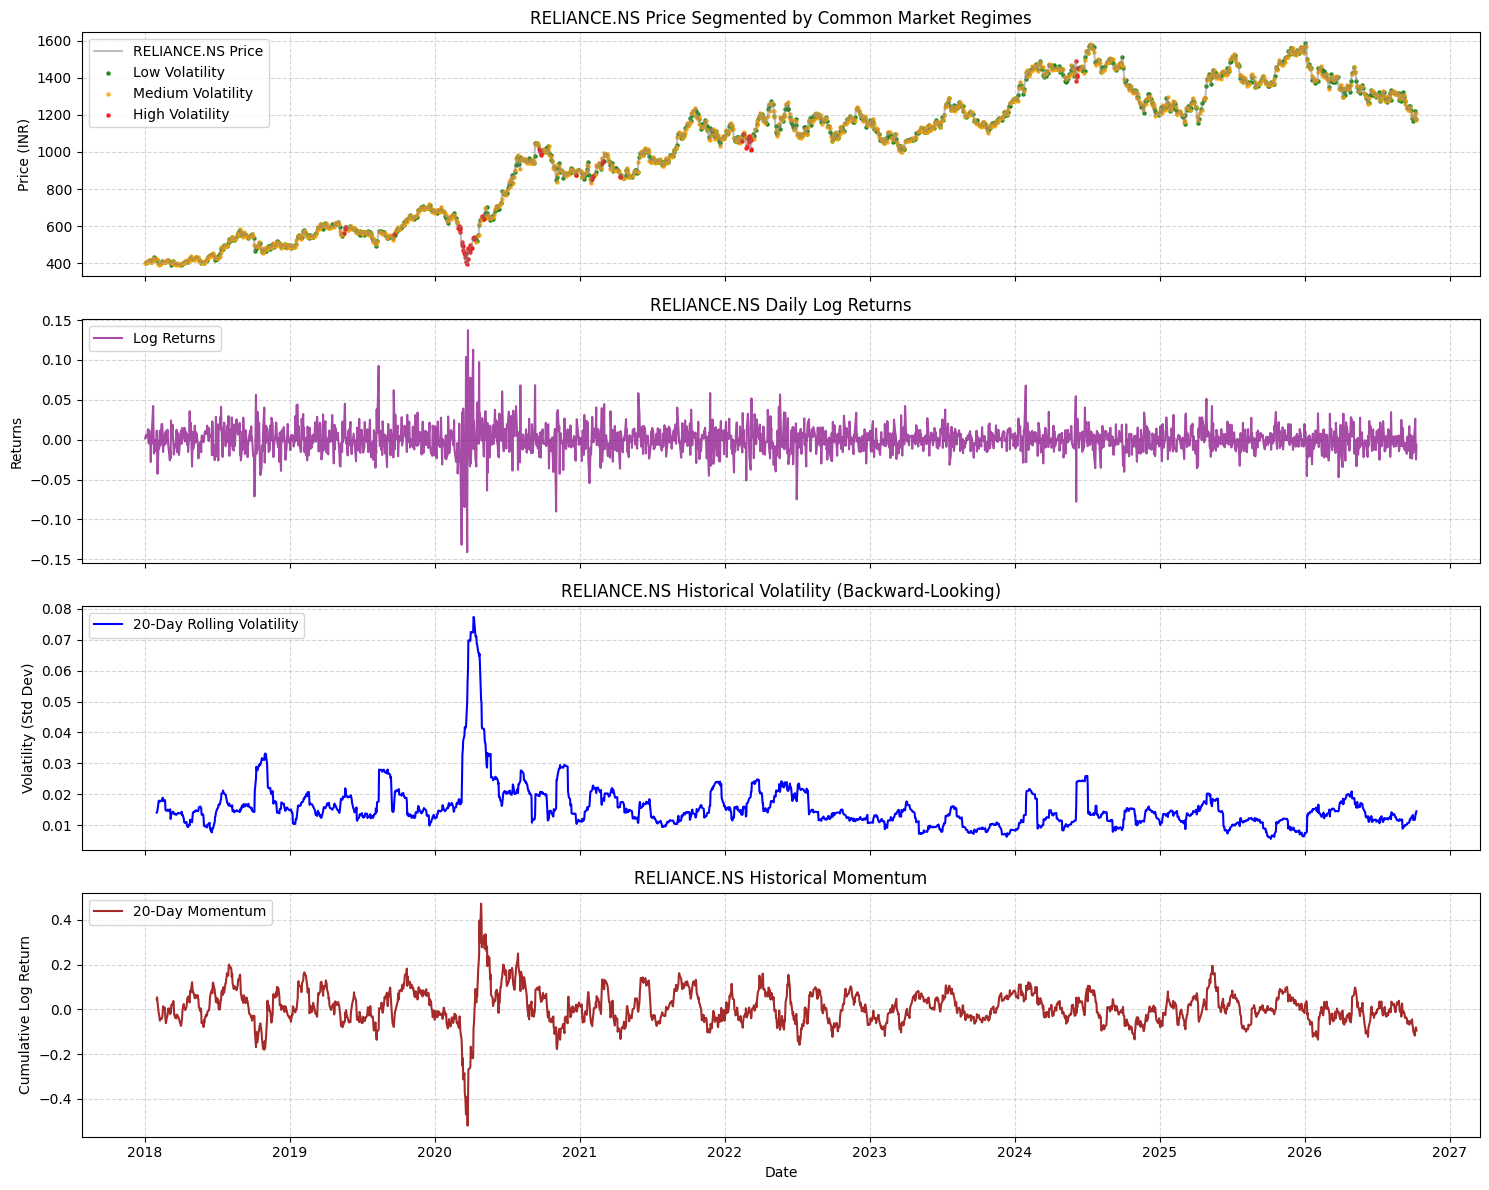

In [7]:
import matplotlib.pyplot as plt

# =====================================================================
# VISUALIZE MARKET REGIMES & STOCK FEATURES
# =====================================================================
test_stock = SELECTED_UNIVERSE[0] # RELIANCE.NS
plot_df = stock_dfs[test_stock].copy()

# Define a color map for the 3 sorted volatility regimes
colors = {0: "green", 1: "orange", 2: "red"}
labels = {0: "Low Volatility", 1: "Medium Volatility", 2: "High Volatility"}

fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

# Plot 1: Stock Price colored by Market Regime
axes[0].plot(plot_df.index, plot_df["Price"], color="gray", alpha=0.5, label=f"{test_stock} Price")
for regime in [0, 1, 2]:
    mask = plot_df["Market_Regime"] == regime
    axes[0].scatter(plot_df.index[mask], plot_df["Price"][mask],
                    color=colors[regime], label=labels[regime], s=5, alpha=0.8)
axes[0].set_title(f"{test_stock} Price Segmented by Common Market Regimes")
axes[0].set_ylabel("Price (INR)")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Stock Log Returns
axes[1].plot(plot_df.index, plot_df["Log_Return"], color="purple", alpha=0.7, label="Log Returns")
axes[1].set_title(f"{test_stock} Daily Log Returns")
axes[1].set_ylabel("Returns")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Rolling Volatility
axes[2].plot(plot_df.index, plot_df["Volatility"], color="blue", label="20-Day Rolling Volatility")
axes[2].set_title(f"{test_stock} Historical Volatility (Backward-Looking)")
axes[2].set_ylabel("Volatility (Std Dev)")
axes[2].legend(loc="upper left")
axes[2].grid(True, linestyle="--", alpha=0.5)

# Plot 4: Momentum
axes[3].plot(plot_df.index, plot_df["Momentum"], color="brown", label="20-Day Momentum")
axes[3].set_title(f"{test_stock} Historical Momentum")
axes[3].set_ylabel("Cumulative Log Return")
axes[3].set_xlabel("Date")
axes[3].legend(loc="upper left")
axes[3].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 2b. Phase 2 - Per-regime parameters, shrinkage, cost function, brute force, simulated annealing (your code)

In [8]:
import numpy as np, pandas as pd, itertools

# Prepare returns_df from features_df to have clean ticker names as columns
log_return_cols = [f"{stock}_log_return" for stock in SELECTED_UNIVERSE]
returns_df = features_df[log_return_cols].copy()
returns_df.columns = SELECTED_UNIVERSE

# Join the 3 market regime probabilities from market_results
probability_cols = [
    "Prob_Market_Regime_0_Low_Vol",
    "Prob_Market_Regime_1_Med_Vol",
    "Prob_Market_Regime_2_High_Vol"
]
returns_df = returns_df.join(market_results[probability_cols], how="inner")

REGIME_COLS = {0: "Prob_Market_Regime_0_Low_Vol",
               1: "Prob_Market_Regime_1_Med_Vol",
               2: "Prob_Market_Regime_2_High_Vol"}
LAMBDA_R = {0: 1.0, 1: 3.0, 2: 6.0}   # risk aversion per regime (your design choice, tune on train only)
K = 5
KAPPA = 0.002                          # cost per flipped holding flag (placeholder, tune)
TRADING_DAYS = 252
stocks = list(SELECTED_UNIVERSE)
N = len(stocks)

def weighted_stats(R, w):
    w = w / w.sum()
    mu = w @ R
    X = R - mu
    S = (X * w[:, None]).T @ X
    return mu, S, X, w

def lw_shrink_identity(S, X, w):
    """Ledoit-Wolf shrinkage toward (avg variance * I), generalized to weighted rows."""
    p = S.shape[0]
    F = (np.trace(S) / p) * np.eye(p)
    d2 = np.sum((S - F) ** 2) / p
    sq = np.einsum('ti,ti->t', X, X)
    xSx = np.einsum('ti,ij,tj->t', X, S, X)
    dev = sq**2 - 2 * xSx + np.sum(S**2)          # ||x x^T - S||_F^2 per day
    b2 = min(np.sum(w**2 * dev) / p, d2)
    delta = b2 / d2 if d2 > 0 else 1.0
    return (1 - delta) * S + delta * F, delta

def fit_regime_params(returns_df, asof):
    """Uses data up to and including `asof` only."""
    hist = returns_df.loc[:asof]
    R = np.expm1(hist[stocks].to_numpy())          # log -> simple returns (portfolio returns add in simple terms)
    out = {}
    for r, col in REGIME_COLS.items():
        mu, S, X, wn = weighted_stats(R, hist[col].to_numpy())
        S_shr, delta = lw_shrink_identity(S, X, wn)
        out[r] = dict(mu=mu * TRADING_DAYS, Sigma=S_shr * TRADING_DAYS,
                      delta=delta, n_eff=1.0 / np.sum(wn**2))
    return out

def blend(fit, p):
    p = np.asarray(p, float); p = p / p.sum()
    mu_t = sum(p[r] * fit[r]["mu"] for r in REGIME_COLS)
    Sigma_t = sum(p[r] * fit[r]["Sigma"] for r in REGIME_COLS)
    lam_t = sum(p[r] * LAMBDA_R[r] for r in REGIME_COLS)
    return mu_t, Sigma_t, lam_t

def build_objective(mu_t, Sigma_t, lam_t, K, kappa, x_prev):
    # cost(x) = lam * w'Σw - mu'w + kappa * sum (x - x_prev)^2, with w = x / K
    Q = lam_t / K**2 * Sigma_t
    lin = -mu_t / K + kappa * (1 - 2 * x_prev)    # turnover term folded in (binary: x^2 = x)
    const = kappa * np.sum(x_prev)
    def cost(X):
        X = np.atleast_2d(X).astype(float)
        c = np.einsum('mi,ij,mj->m', X, Q, X) + X @ lin + const
        return c if c.size > 1 else c[0]
    return dict(Q=Q, lin=lin, const=const, cost=cost, K=K)

def brute_force(obj, N, K):
    combos = np.array(list(itertools.combinations(range(N), K)))
    X = np.zeros((len(combos), N))
    X[np.arange(len(combos))[:, None], combos] = 1
    costs = obj["cost"](X)
    i = costs.argmin()
    return dict(x=X[i], cost=costs[i], all_costs=costs)

def approx_ratio(c_found, all_costs):
    return (all_costs.max() - c_found) / (all_costs.max() - all_costs.min())

def _swap(x, rng):
    y = x.copy()
    i = rng.choice(np.flatnonzero(y == 1)); j = rng.choice(np.flatnonzero(y == 0))
    y[i], y[j] = 0, 1
    return y

def simulated_annealing(obj, N, K, n_iter=5000, seed=0, t_end_frac=1e-3):
    rng = np.random.default_rng(seed); cost = obj["cost"]
    x = np.zeros(N); x[rng.choice(N, K, replace=False)] = 1
    c = cost(x)
    T = max(np.mean([abs(cost(_swap(x, rng)) - c) for _ in range(200)]), 1e-9)
    alpha = t_end_frac ** (1.0 / n_iter)
    best_x, best_c = x.copy(), c
    for _ in range(n_iter):
        y = _swap(x, rng); cy = cost(y); d = cy - c
        if d < 0 or rng.random() < np.exp(-d / T):
            x, c = y, cy
            if c < best_c: best_x, best_c = x.copy(), c
        T *= alpha
    return dict(x=best_x, cost=best_c)

def solve_at(asof, returns_df, x_prev=None, solver="brute", **kw):
    fit = fit_regime_params(returns_df, asof)
    p = returns_df.loc[asof, list(REGIME_COLS.values())].to_numpy(float)
    mu_t, Sigma_t, lam_t = blend(fit, p)
    x_prev = np.zeros(N) if x_prev is None else x_prev
    obj = build_objective(mu_t, Sigma_t, lam_t, K, KAPPA, x_prev)
    res = brute_force(obj, N, K) if solver == "brute" else simulated_annealing(obj, N, K, **kw)
    res["picked"] = [s for s, v in zip(stocks, res["x"]) if v == 1]
    res["obj"], res["fit"], res["p"] = obj, fit, p
    return res

asof = returns_df.index[-1]
bf = solve_at(asof, returns_df)
print("Optimized selection at asof:", bf["picked"], bf["cost"])

# 1. probabilities sum to 1
assert np.allclose(returns_df[list(REGIME_COLS.values())].sum(axis=1), 1, atol=1e-6)

# 2. covariance sanity, plus regime ordering by volatility
fit = bf["fit"]
for r in REGIME_COLS:
    S_val = fit[r]["Sigma"]
    print(r, "sym:", np.allclose(S_val, S_val.T), "min eig:", np.linalg.eigvalsh(S_val).min().round(6),
          "delta:", round(fit[r]["delta"], 3), "n_eff:", round(fit[r]["n_eff"]),
          "avg vol:", np.sqrt(np.diag(S_val)).mean().round(3))

# 3. QUBO expansion matches the explicit formula on every subset
obj = bf["obj"]; x_prev = np.zeros(N); x_prev[:K] = 1
mu_t, Sigma_t, lam_t = blend(fit, bf["p"])
o2 = build_objective(mu_t, Sigma_t, lam_t, K, KAPPA, x_prev)
for c in itertools.combinations(range(N), K):
    x = np.zeros(N); x[list(c)] = 1; w = x / K
    direct = lam_t * w @ Sigma_t @ w - mu_t @ w + KAPPA * np.sum((x - x_prev) ** 2)
    assert np.isclose(o2["cost"](x), direct)

# 4. SA never beats brute force, and how often it finds the optimum
bf2 = brute_force(o2, N, K)
sa = [simulated_annealing(o2, N, K, seed=s) for s in range(20)]
assert all(r["cost"] >= bf2["cost"] - 1e-12 for r in sa)
print("SA hit rate:", np.mean([np.isclose(r["cost"], bf2["cost"]) for r in sa]),
      "mean AR:", np.mean([approx_ratio(r["cost"], bf2["all_costs"]) for r in sa]))

Optimized selection at asof: ['SBIN.NS', 'BHARTIARTL.NS', 'M&M.NS', 'SUNPHARMA.NS', 'POWERGRID.NS'] -0.15793117433072645
0 sym: True min eig: 0.02878 delta: 0.018 n_eff: 1663 avg vol: 0.241
1 sym: True min eig: 0.029395 delta: 0.016 n_eff: 1676 avg vol: 0.243
2 sym: True min eig: 0.0816 delta: 0.064 n_eff: 129 avg vol: 0.63


SA hit rate: 1.0 mean AR: 1.0


### Ising conversion with the K-constraint penalty (your code)

In [9]:
# Store the cost function in another variable
obj_dict = bf["obj"]

def build_ising_hamiltonian(obj_dict, P=50.0):
    Q = obj_dict['Q']
    lin = obj_dict['lin']
    const = obj_dict['const']
    K = obj_dict['K']
    N = len(lin)

    # 1. Fold penalty P * (sum(x) - K)^2 into QUBO terms
    Q_tot = Q + P * np.ones((N, N))
    lin_tot = lin - 2.0 * P * K * np.ones(N)
    const_tot = const + P * (K ** 2)

    # Symmetrize total quadratic matrix
    Q_sym = (Q_tot + Q_tot.T) / 2.0

    # 2. Convert x_i -> (1 - z_i) / 2
    h = np.zeros(N)
    J = np.zeros((N, N))
    C_offset = float(const_tot)

    # Process linear and diagonal terms (since x_i^2 = x_i)
    for i in range(N):
        l_eff = lin_tot[i] + Q_sym[i, i]
        h[i] -= 0.5 * l_eff
        C_offset += 0.5 * l_eff

    # Process off-diagonal quadratic pair terms
    for i in range(N):
        for j in range(i + 1, N):
            q_val = 2.0 * Q_sym[i, j]  # Pair interaction weight

            J[i, j] = q_val / 4.0
            J[j, i] = J[i, j]

            h[i] -= q_val / 4.0
            h[j] -= q_val / 4.0
            C_offset += q_val / 4.0

    return h, J, C_offset

build_ising_hamiltonian(obj_dict)

(array([-24.99174433, -24.99208901, -24.99883863, -24.99791192,
        -24.99253175, -24.98903767, -24.98862536, -24.98962144,
        -24.99034372, -24.99557606, -24.9883832 ]),
 array([[ 0.        , 25.00075261, 25.00098983, 25.0006115 , 25.00106469,
         25.00123019, 25.000892  , 25.00122165, 25.00075115, 25.00102518,
         25.0007478 ],
        [25.00075261,  0.        , 25.00053282, 25.00053973, 25.00065761,
         25.00049978, 25.00043102, 25.00075885, 25.00050366, 25.00060541,
         25.00030906],
        [25.00098983, 25.00053282,  0.        , 25.0005264 , 25.00117247,
         25.00134584, 25.00074715, 25.00119278, 25.0004278 , 25.00101953,
         25.00057112],
        [25.0006115 , 25.00053973, 25.0005264 ,  0.        , 25.00055113,
         25.00045033, 25.00050057, 25.00060932, 25.0003939 , 25.00072555,
         25.00031216],
        [25.00106469, 25.00065761, 25.00117247, 25.00055113,  0.        ,
         25.00164447, 25.00090827, 25.00149452, 25.00076355, 2

## Phase 3A - Leak-free walk-forward regime inference

In [10]:
# ======================= PHASE 3A: LEAK-FREE WALK-FORWARD REGIMES =======================
import numpy as np, pandas as pd, itertools, time
from scipy.stats import norm
from hmmlearn import hmm

PROB_COLS = [REGIME_COLS[r] for r in range(3)]
MIN_TRAIN, REFIT_EVERY, REBAL_EVERY = 504, CFG["refit"], CFG["rebal"]     # ~2y initial train, quarterly refit, monthly rebalance
COST_BPS = 10.0                                        # one-way cost per unit of traded weight (10 bps)

mkt_ret = returns_df[stocks].mean(axis=1)              # equal-weight market proxy (same series your HMM used)

def fit_market_hmm(x_train, n_init=3, seed=42):
    best = None
    for s in range(n_init):
        m = hmm.GaussianHMM(3, covariance_type="diag", n_iter=200, random_state=seed + s).fit(x_train)
        ll = m.score(x_train)
        if best is None or ll > best[0]: best = (ll, m)
    m = best[1]
    var = np.asarray(m.covars_).reshape(3, -1)[:, 0]
    return m, np.argsort(var)                          # order states low -> high variance (a model parameter, not data)

def filtered_posteriors(m, x, order):
    """Forward algorithm: p_t = P(s_t | x_1..x_t) with frozen parameters. No future data (unlike predict_proba)."""
    var = np.asarray(m.covars_).reshape(3, -1)[:, 0][order]
    mean = m.means_.reshape(3, -1)[:, 0][order]
    A = m.transmat_[np.ix_(order, order)]; pi = m.startprob_[order]
    lik = norm.pdf(np.asarray(x).reshape(-1, 1), mean, np.sqrt(var))     # (T,3)
    out = np.zeros_like(lik); a = pi * lik[0]; out[0] = a / a.sum()
    for t in range(1, len(lik)):
        a = (out[t - 1] @ A) * lik[t]; s = a.sum()
        out[t] = a / s if s > 0 else out[t - 1] @ A
    return out

def hmm_panel(train_end, block_end):
    """Probabilities for rows [0, block_end) from an HMM trained on rows [0, train_end) only."""
    x = mkt_ret.to_numpy()[:, None]
    m, order = fit_market_hmm(x[:train_end])
    P = filtered_posteriors(m, x[:block_end], order)
    return pd.DataFrame(P, index=returns_df.index[:block_end], columns=PROB_COLS)

def threshold_panel(train_end, block_end, win=20, q=(1/3, 2/3), min_periods=60):
    """Non-quantum ablation: expanding-quantile volatility buckets (past-only), one-hot probabilities."""
    vol = mkt_ret.rolling(win, min_periods=5).std()
    lo = vol.expanding(min_periods).quantile(q[0]); hi = vol.expanding(min_periods).quantile(q[1])
    reg = pd.Series(1, index=vol.index); reg[vol <= lo] = 0; reg[vol >= hi] = 2
    P = np.eye(3)[reg.to_numpy()]
    P[:min_periods] = 1 / 3
    return pd.DataFrame(P[:block_end], index=returns_df.index[:block_end], columns=PROB_COLS)

def refit_points(n, min_train=MIN_TRAIN, every=REFIT_EVERY):
    pts = list(range(min_train, n, every)); return pts

def build_panels(panel_fn, n=None):
    """Dict: refit_point R -> prob panel over rows [0, next_refit) from a model trained on rows [0, R)."""
    n = n or len(returns_df); pts = refit_points(n); panels = {}
    for k, R in enumerate(pts):
        end = pts[k + 1] if k + 1 < len(pts) else n
        panels[R] = panel_fn(R, end)
    return panels


## Phase 3B - Solver-agnostic backtest harness

In [11]:
# ======================= PHASE 3B: SOLVER-AGNOSTIC BACKTEST HARNESS =======================
def make_objective_at(df_probs, i, x_prev):
    """Objective for the rebalance at row i using ONLY rows <= i (reuses your fit_regime_params / blend / build_objective)."""
    asof = df_probs.index[i]
    fit = fit_regime_params(df_probs, asof)
    p = df_probs.iloc[i][PROB_COLS].to_numpy(float)
    mu_t, Sigma_t, lam_t = blend(fit, p)
    return build_objective(mu_t, Sigma_t, lam_t, K, KAPPA, x_prev), dict(fit=fit, p=p, mu=mu_t, Sigma=Sigma_t, lam=lam_t)

def solver_brute(obj, ctx): return brute_force(obj, N, K)["x"]
def solver_sa(obj, ctx, n_iter=3000): return simulated_annealing(obj, N, K, n_iter=n_iter, seed=ctx["i"])["x"]

def run_backtest(panels, solver, label, rebal_every=REBAL_EVERY, cost_bps=COST_BPS, verbose=False):
    n = len(returns_df); pts = sorted(panels); R_simple = np.expm1(returns_df[stocks].to_numpy())
    dates = list(range(pts[0], n - 1, rebal_every))
    x_prev = np.zeros(N); w_prev = np.zeros(N)
    daily = pd.Series(0.0, index=returns_df.index); rec = []
    for i in dates:
        Rb = max(p for p in pts if p <= i)                          # latest refit available at date i
        df_p = returns_df[stocks].join(panels[Rb], how="inner")
        obj, ctx = make_objective_at(df_p, i, x_prev); ctx["i"] = i; ctx["refit"] = Rb
        x = np.asarray(solver(obj, ctx), float)
        assert x.sum() == K, "solver returned an infeasible portfolio"
        w = x / K; turnover = np.abs(w - w_prev).sum()
        j_end = min(i + rebal_every, n - 1)
        r = R_simple[i + 1: j_end + 1] @ w                           # hold from i+1 to next rebalance
        r = r.copy(); r[0] -= cost_bps / 1e4 * turnover               # cost paid on the first holding day
        daily.iloc[i + 1: j_end + 1] = r
        rec.append(dict(date=returns_df.index[i], turnover=turnover, picked=tuple(np.flatnonzero(x)), n_changed=int(np.abs(x - x_prev).sum() / 2)))
        x_prev, w_prev = x, w
    daily = daily.iloc[dates[0] + 1:]
    return dict(label=label, daily=daily, rebal=pd.DataFrame(rec), panels_used=pts)

def benchmark_equal_weight(start_row, rebal_every=REBAL_EVERY, cost_bps=COST_BPS):
    n = len(returns_df); R_simple = np.expm1(returns_df[stocks].to_numpy()); w = np.ones(N) / N
    daily = pd.Series(R_simple[start_row + 1:] @ w, index=returns_df.index[start_row + 1:])
    return dict(label="Equal-weight 1/N (all 11)", daily=daily, rebal=pd.DataFrame(dict(turnover=[0.0])))

def metrics(res, bench_daily):
    r = res["daily"]; ann = 252
    sharpe = r.mean() / r.std() * np.sqrt(ann) if r.std() > 0 else np.nan
    eq = (1 + r).cumprod(); mdd = (eq / eq.cummax() - 1).min()
    te = (r - bench_daily.reindex(r.index)).std() * np.sqrt(ann)
    return dict(Strategy=res["label"], Sharpe=round(sharpe, 3), AnnReturn=round((1 + r).prod() ** (ann / len(r)) - 1, 4),
                MaxDD=round(mdd, 3), TrackErr=round(te, 4), AvgTurnover=round(res["rebal"]["turnover"].mean(), 3))

def summarize(results, bench):
    return pd.DataFrame([metrics(r, bench["daily"]) for r in results + [bench]]).set_index("Strategy")


### Run Phase 3: panels, leakage tests, classical backtests

27 refit points, built in 2.7s
Filtered posteriors: max change in past rows when the future changes = 0.00e+00  (must be 0)
Smoothed (predict_proba): max change in past rows when the future changes = 0.254  (leakage)


,Sharpe,AnnReturn,MaxDD,TrackErr,AvgTurnover
Strategy,,,,,
HMM + Brute force,0.724,0.1228,-0.290,0.0781,0.173
HMM + Simulated annealing,0.724,0.1228,-0.290,0.0781,0.173
Equal-weight 1/N (all 11),1.003,0.1683,-0.327,0.0000,0.000


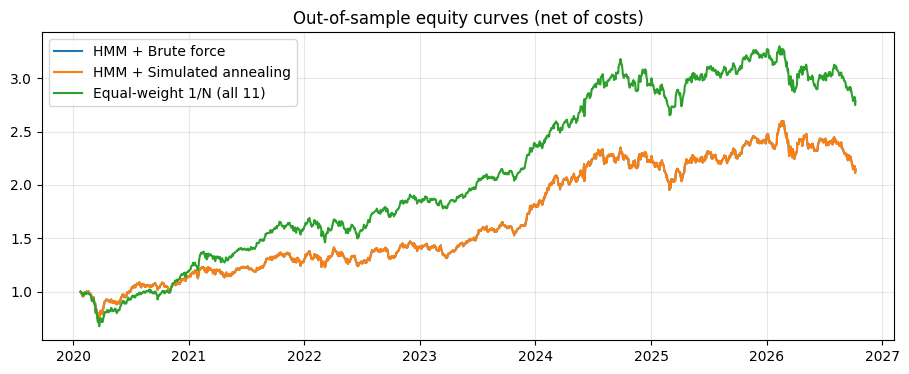

In [12]:
import matplotlib.pyplot as plt
t0 = time.time()
panels_hmm = build_panels(hmm_panel)          # refit every 63 days on rows < R, filtered posteriors only
panels_thr = build_panels(threshold_panel)
print(f"{len(panels_hmm)} refit points, built in {time.time()-t0:.1f}s")

# ---- leakage tests ----
def leakage_tests():
    global mkt_ret
    R = sorted(panels_hmm)[2]
    base = hmm_panel(R, R + 63).iloc[:R + 5]
    orig = mkt_ret.copy(); mkt_ret = orig.copy(); mkt_ret.iloc[R + 5:] += 0.05            # perturb the FUTURE (after row R+5)
    alt = hmm_panel(R, R + 63).iloc[:R + 5]; mkt_ret = orig
    d_filtered = float(np.abs(alt.values - base.values).max())
    x = orig.to_numpy()[:, None]; x2 = x.copy(); x2[R + 5:] += 0.05
    m1 = hmm.GaussianHMM(3, covariance_type="diag", n_iter=100, random_state=42).fit(x[:R])
    d_smoothed = float(np.abs(m1.predict_proba(x[:R + 63])[:R + 5] - m1.predict_proba(x2[:R + 63])[:R + 5]).max())
    print(f"Filtered posteriors: max change in past rows when the future changes = {d_filtered:.2e}  (must be 0)")
    print(f"Smoothed (predict_proba): max change in past rows when the future changes = {d_smoothed:.3f}  (leakage)")
    assert d_filtered < 1e-12 and d_smoothed > 1e-6
leakage_tests()

# ---- classical backtests (brute force = exact optimum, SA = heuristic) ----
bt_bf = run_backtest(panels_hmm, solver_brute, "HMM + Brute force")
bt_sa = run_backtest(panels_hmm, solver_sa, "HMM + Simulated annealing")
bench = benchmark_equal_weight(sorted(panels_hmm)[0])
tab3 = summarize([bt_bf, bt_sa], bench); display(tab3)

fig, ax = plt.subplots(figsize=(11, 4))
for r in (bt_bf, bt_sa, bench): ax.plot((1 + r["daily"]).cumprod(), label=r["label"])
ax.set_title("Out-of-sample equity curves (net of costs)"); ax.legend(); ax.grid(alpha=.3); plt.show()

## Phase 4 - Ising verification, fast simulator, Qiskit circuits, penalty QAOA baseline
Conventions: qubit *i* = asset *i* = bit *i* of the bitstring index (Qiskit little-endian), `x = (1 - z)/2`, cost layer `exp(-i*gamma*H_C)`, mixer `exp(-i*beta*sum X)` or the XY ring. Optimisation runs on a fast exact numpy simulator that is **cross-checked against Qiskit `Statevector`** below.

In [13]:
# ======================= PHASE 4: ISING VERIFICATION, FAST SIMULATOR, QISKIT CIRCUITS, PENALTY QAOA =======================
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import XXPlusYYGate, RYGate
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize

BITS = None
def _bits(n):
    global BITS
    if BITS is None or BITS.shape[1] != n:
        b = np.arange(2 ** n)
        BITS = ((b[:, None] >> np.arange(n)) & 1).astype(np.int8)       # BITS[b, i] = x_i (qubit i = bit i, Qiskit little-endian)
    return BITS

def ising_energies(h, J, c):
    """Energy of every bitstring: E = sum h_i z_i + sum_{i<j} J_ij z_i z_j + c, with z = 1 - 2x."""
    Z = 1.0 - 2.0 * _bits(len(h))
    return Z @ h + 0.5 * np.einsum('bi,ij,bj->b', Z, J, Z) + c

def normalize_obj(obj, n_samples=2000, seed=0):
    """z-score the cost over RANDOM FEASIBLE subsets (no brute force needed) so gamma ranges are comparable across dates."""
    rng = np.random.default_rng(seed)
    X = np.zeros((n_samples, N))
    for s in range(n_samples): X[s, rng.choice(N, K, replace=False)] = 1
    c = obj["cost"](X); mu, sd = c.mean(), c.std()
    return dict(Q=obj["Q"] / sd, lin=obj["lin"] / sd, const=(obj["const"] - mu) / sd, K=obj["K"]), (mu, sd)

class Instance:
    """One portfolio-selection instance in QAOA form. Energies are z-scored: a random feasible subset has mean 0, std 1."""
    def __init__(self, obj, P_pen=4.0):
        self.obj = obj; self.nobj, self.norm = normalize_obj(obj)
        self.h, self.J, self.c = build_ising_hamiltonian(self.nobj, P=0.0)           # constraint handled by XY mixer
        self.hp, self.Jp, self.cp = build_ising_hamiltonian(self.nobj, P=P_pen)      # penalty version for the baseline
        self.E_xy = ising_energies(self.h, self.J, self.c); self.E_pen = ising_energies(self.hp, self.Jp, self.cp)
        self.feas = _bits(N).sum(1) == K
        Ef = np.where(self.feas, self.E_xy, np.inf)
        self.opt = int(np.argmin(Ef)); self.Emin = Ef[self.opt]
        self.Emax = self.E_xy[self.feas].max()
        self.P_pen = P_pen
    def AR(self, E):  return (self.Emax - E) / (self.Emax - self.Emin)               # 1 = optimal, 0 = worst feasible
    def bitstring(self, b): return _bits(N)[b].astype(float)

def verify_ising(inst, n_check=300, seed=1):
    rng = np.random.default_rng(seed); B = _bits(N)
    for b in rng.integers(0, 2 ** N, n_check):
        x = B[b].astype(float)
        assert np.isclose(inst.E_xy[b], x @ inst.nobj["Q"] @ x + x @ inst.nobj["lin"] + inst.nobj["const"]), "Ising != QUBO"
        pen = inst.P_pen * (x.sum() - K) ** 2
        assert np.isclose(inst.E_pen[b], inst.E_xy[b] + pen), "penalty Ising != QUBO + penalty"
    assert np.isclose(inst.Emin, (brute_force(inst.obj, N, K)["cost"] - inst.norm[0]) / inst.norm[1]), "optimum mismatch vs brute force"
    return True

# ---------------- fast exact simulator (numpy), cross-checked against Qiskit below ----------------
def ring_edges(n):
    e = [(i, i + 1) for i in range(0, n - 1, 2)] + [(i, i + 1) for i in range(1, n - 1, 2)]
    return e + [(n - 1, 0)] if n > 2 else e
_PAIR_IDX = {}
def _pair_idx(n, i, j):
    key = (n, i, j)
    if key not in _PAIR_IDX:
        b = np.arange(2 ** n); bi = (b >> i) & 1; bj = (b >> j) & 1
        _PAIR_IDX[key] = (b[(bi == 1) & (bj == 0)], b[(bi == 0) & (bj == 1)])
    return _PAIR_IDX[key]

def apply_xy(psi, i, j, beta):
    """exp(-i beta (XX+YY)/2) on qubits i,j: rotates within span{|01>,|10>}, leaves |00>,|11>. Preserves Hamming weight."""
    a_idx, b_idx = _pair_idx(N, i, j); a, b = psi[a_idx], psi[b_idx]
    c, s = np.cos(beta), -1j * np.sin(beta)
    psi[a_idx] = c * a + s * b; psi[b_idx] = c * b + s * a

def apply_rx_all(psi, beta):
    c, s = np.cos(beta), -1j * np.sin(beta); t = psi.reshape((2,) * N)
    for ax in range(N):
        a = np.take(t, 0, axis=ax); b = np.take(t, 1, axis=ax)
        t = np.stack([c * a + s * b, s * a + c * b], axis=ax)
    return t.reshape(-1)

DICKE = None
def dicke_state():
    v = (_bits(N).sum(1) == K).astype(complex); return v / np.linalg.norm(v)

def qaoa_probs(theta, p, inst, mode):
    """theta = [gamma_1..gamma_p, beta_1..beta_p]. mode 'xy': Dicke start + XY ring mixer on E_xy.  mode 'penalty': |+>^N + RX mixer on E_pen."""
    g, b = theta[:p], theta[p:]
    if mode == "xy": psi = dicke_state(); E = inst.E_xy
    else: psi = np.full(2 ** N, 2 ** (-N / 2), dtype=complex); E = inst.E_pen
    edges = ring_edges(N)
    for l in range(p):
        psi = psi * np.exp(-1j * g[l] * E)
        if mode == "xy":
            psi = psi.copy()
            for (i, j) in edges: apply_xy(psi, i, j, b[l])
        else: psi = apply_rx_all(psi, b[l])
    pr = np.abs(psi) ** 2; return pr / pr.sum()

def cvar(E, pr, alpha):
    """Mean energy of the best alpha-fraction of probability mass. alpha=1 -> ordinary expectation."""
    if alpha >= 1: return float(pr @ E)
    o = np.argsort(E, kind="stable"); cum = np.cumsum(pr[o]); take = np.minimum(pr[o], np.clip(alpha - (cum - pr[o]), 0, None))
    return float(take @ E[o] / alpha)

# ---------------- Qiskit circuits (for resource counts, hardware, and cross-checking the fast simulator) ----------------
def dicke_circuit(n, k):
    """Bartschi-Eidenbenz deterministic Dicke-state preparation. Qubits are 1-indexed in the paper; qubit q <-> Qiskit index q-1."""
    qc = QuantumCircuit(n)
    for q in range(n - k + 1, n + 1): qc.x(q - 1)                       # |0^{n-k} 1^k>
    def scs(m, kk):                                                       # SCS_{m,kk} acts on qubits m-kk..m
        # gate (i): qubits m-1, m
        qc.cx(m - 2, m - 1); qc.append(RYGate(2 * np.arccos(np.sqrt(1.0 / m))).control(1), [m - 1, m - 2]); qc.cx(m - 2, m - 1)
        for l in range(2, kk + 1):                                        # gates (ii)_l
            qc.cx(m - l - 1, m - 1)
            qc.append(RYGate(2 * np.arccos(np.sqrt(l / m))).control(2), [m - 1, m - l, m - l - 1])
            qc.cx(m - l - 1, m - 1)
    for m in range(n, k, -1): scs(m, k)
    for m in range(k, 1, -1): scs(m, m - 1)
    return qc

def qaoa_circuit(theta, p, inst, mode):
    g, b = theta[:p], theta[p:]; qc = QuantumCircuit(N)
    h, J, E = (inst.h, inst.J, "xy") if mode == "xy" else (inst.hp, inst.Jp, "pen")
    if mode == "xy": qc.compose(dicke_circuit(N, K), inplace=True)
    else: qc.h(range(N))
    for l in range(p):
        for i in range(N):
            if abs(h[i]) > 1e-12: qc.rz(2 * g[l] * h[i], i)
        for i in range(N):
            for j in range(i + 1, N):
                if abs(J[i, j]) > 1e-12: qc.rzz(2 * g[l] * J[i, j], i, j)
        if mode == "xy":
            for (i, j) in ring_edges(N): qc.append(XXPlusYYGate(2 * b[l]), [i, j])
        else: qc.rx(2 * b[l], range(N))
    return qc

def resources(theta, p, inst, mode):
    qc = qaoa_circuit(theta, p, inst, mode)
    tq = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=0)
    return dict(depth=tq.depth(), cx=tq.count_ops().get("cx", 0), total_gates=sum(tq.count_ops().values()))

def crosscheck_qiskit(inst, p=2, seed=0):
    rng = np.random.default_rng(seed); th = rng.uniform(0.1, 1.0, 2 * p)
    D = Statevector.from_instruction(dicke_circuit(N, K)).data
    assert np.allclose(np.abs(D) ** 2, np.abs(dicke_state()) ** 2, atol=1e-9), "Dicke circuit != Dicke state"
    for mode in ("xy", "penalty"):
        pq = np.abs(Statevector.from_instruction(qaoa_circuit(th, p, inst, mode)).data) ** 2
        assert np.allclose(pq, qaoa_probs(th, p, inst, mode), atol=1e-8), f"Qiskit circuit != numpy simulator ({mode})"
    return True


In [14]:
# pick one real instance (a rebalance date late in the sample) and verify everything
Rb = sorted(panels_hmm)[3]; i0 = Rb + 10
df_p = returns_df[stocks].join(panels_hmm[Rb], how="inner")
obj0, ctx0 = make_objective_at(df_p, i0, np.zeros(N))
inst0 = Instance(obj0)
print("Ising energies == QUBO cost (and penalty version == cost + P*(sum x - K)^2), optimum == brute force:", verify_ising(inst0))
print("Qiskit circuits == numpy simulator (Dicke state, XY-QAOA, penalty-QAOA):", crosscheck_qiskit(inst0))
d = dicke_circuit(N, K); tq = transpile(d, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=0)
print(f"Dicke-state prep alone: depth {tq.depth()}, CX count {tq.count_ops().get('cx', 0)}")

Ising energies == QUBO cost (and penalty version == cost + P*(sum x - K)^2), optimum == brute force: True
Qiskit circuits == numpy simulator (Dicke state, XY-QAOA, penalty-QAOA): True


Dicke-state prep alone: depth 695, CX count 340


## Phase 5 - Constraint-preserving CVaR-QAOA and the RQ2 experiment
Four configurations are compared: {penalty + X mixer, Dicke + XY mixer} x {expectation, CVaR}. **A uniform-random-feasible-sampling baseline is included on purpose**: at N = 11 there are only 462 feasible subsets, so "best of many shots" is easy for any sampler. The informative numbers are `p_opt` (lift over 1/462), `exp_AR`, and `feasible_prob`.

In [15]:
# ======================= PHASE 5: CVaR-QAOA OPTIMIZER, METRICS, RQ2 EXPERIMENT =======================
ALPHA = 0.2          # CVaR fraction (alpha=1 -> plain expectation)
GAMMA_MAX, BETA_MAX = 2.0, 1.0

def run_qaoa(inst, mode="xy", p=2, alpha=ALPHA, restarts=3, seed=0, init=None, maxiter=200, shots=None):
    """COBYLA over (gammas, betas). `init` = list of starting points (warm start); otherwise random restarts.
    shots=None -> exact probabilities inside the optimizer; shots=int -> finite-shot CVaR (noisy objective)."""
    E = inst.E_xy if mode == "xy" else inst.E_pen
    rng = np.random.default_rng(seed); best = None; nfev_total = 0
    starts = [np.asarray(s, float) for s in init] if init is not None else \
             [np.r_[rng.uniform(0, GAMMA_MAX, p), rng.uniform(0, BETA_MAX, p)] for _ in range(restarts)]
    for th0 in starts:
        hist = []
        def f(th):
            pr = qaoa_probs(th, p, inst, mode)
            if shots: pr = rng.multinomial(shots, pr) / shots
            hist.append(float(pr @ E)); return cvar(E, pr, alpha)
        r = minimize(f, th0, method="COBYLA", options=dict(maxiter=maxiter, rhobeg=0.3, tol=1e-4))
        nfev_total += r.nfev
        if best is None or r.fun < best["fun"]: best = dict(fun=r.fun, theta=r.x, hist=hist, nfev=r.nfev)
    best["nfev_total"] = nfev_total; best["mode"] = mode; best["p"] = p
    return best

def evaluate(inst, theta, p, mode, shots=64, seed=0):
    """Quality metrics from the final state."""
    pr = qaoa_probs(theta, p, inst, mode); feas = inst.feas
    pf = pr[feas].sum(); AR_b = inst.AR(inst.E_xy)
    exp_AR = float((pr[feas] * AR_b[feas]).sum() / pf) if pf > 0 else 0.0
    rng = np.random.default_rng(seed); s = rng.choice(2 ** N, size=shots, p=pr); sf = s[feas[s]]
    best_AR = float(AR_b[sf].max()) if len(sf) else 0.0
    best_b = int(sf[np.argmin(inst.E_xy[sf])]) if len(sf) else None
    return dict(feasible_prob=float(pf), p_opt=float(pr[inst.opt]), exp_AR=exp_AR, best_of_shots_AR=best_AR, best_b=best_b)

def random_baseline(inst, shots=64, trials=300, seed=0):
    """Uniform sampling over feasible subsets: the bar any quantum sampler has to clear."""
    rng = np.random.default_rng(seed); AR_b = inst.AR(inst.E_xy); idx = np.flatnonzero(inst.feas)
    best = [AR_b[rng.choice(idx, shots)].max() for _ in range(trials)]
    return dict(feasible_prob=1.0, p_opt=1 / len(idx), exp_AR=float(AR_b[idx].mean()), best_of_shots_AR=float(np.mean(best)))

def select_from_samples(inst, theta, p, mode, shots=1024, seed=0):
    """What you would do on hardware: sample, keep feasible bitstrings, return the lowest-cost one."""
    pr = qaoa_probs(theta, p, inst, mode); s = np.random.default_rng(seed).choice(2 ** N, size=shots, p=pr)
    sf = s[inst.feas[s]]
    return inst.bitstring(int(sf[np.argmin(inst.E_xy[sf])])) if len(sf) else None

def gap_curve(inst, hist):
    """Normalized gap of expected energy: 1 = random feasible subset (E=0), 0 = optimum."""
    return (np.array(hist) - inst.Emin) / (0 - inst.Emin)

def evals_to_gap(inst, hist, target=0.5):
    g = gap_curve(inst, hist); k = np.flatnonzero(g <= target)
    return int(k[0] + 1) if len(k) else np.nan

def sample_instances(n_inst=6, seed=0):
    """Real instances from the backtest (spread over the test period), built with the leak-free regime panels."""
    pts = sorted(panels_hmm); n = len(returns_df); dates = list(range(pts[0], n - 1, REBAL_EVERY))
    pick = [dates[int(i)] for i in np.linspace(0, len(dates) - 1, n_inst)]
    out = []
    for i in pick:
        Rb = max(q for q in pts if q <= i); df_p = returns_df[stocks].join(panels_hmm[Rb], how="inner")
        rng = np.random.default_rng(i); xp = np.zeros(N); xp[rng.choice(N, K, replace=False)] = 1
        obj, ctx = make_objective_at(df_p, i, xp); out.append((i, Instance(obj), ctx))
    return out

CONFIGS = {"Penalty + X mixer, expectation": ("penalty", 1.0), "Penalty + X mixer, CVaR": ("penalty", ALPHA),
           "Dicke + XY mixer, expectation": ("xy", 1.0), "Dicke + XY mixer, CVaR": ("xy", ALPHA)}

def rq2_experiment(n_inst=5, n_seeds=2, depths=(1, 2, 3), restarts=2):
    rows = []; insts = sample_instances(n_inst)
    for (i, inst, ctx) in insts:
        for name, (mode, a) in CONFIGS.items():
            for p in depths:
                for s in range(n_seeds):
                    r = run_qaoa(inst, mode, p, a, restarts=restarts, seed=1000 * s + i)
                    m = evaluate(inst, r["theta"], p, mode, seed=s)
                    rows.append(dict(date_row=i, config=name, p=p, seed=s, nfev=r["nfev_total"], **m))
        rb = random_baseline(inst)
        for p in depths: rows.append(dict(date_row=i, config="Random feasible sampling (baseline)", p=p, seed=0, nfev=0, **rb))
    return pd.DataFrame(rows)

def rq2_summary(df):
    g = df.groupby(["config", "p"])[["feasible_prob", "p_opt", "exp_AR", "best_of_shots_AR", "nfev"]].mean().round(3)
    g["opt_lift_vs_random"] = (g["p_opt"] / (1 / 462)).round(1)      # 462 = C(11,5) feasible subsets
    return g


In [16]:
t0 = time.time()
rq2 = rq2_experiment(n_inst=CFG["rq2_inst"], n_seeds=CFG["rq2_seeds"], depths=CFG["rq2_depths"])           # defaults: 5 real instances x 2 seeds x depths 1-3 x 4 configs (scale up for the final study)
print(f"done in {time.time()-t0:.0f}s")
tab5 = rq2_summary(rq2); display(tab5)

# circuit resources after transpilation (angles don't change gate counts)
th_demo = np.array([.3] * 3 + [.4] * 3); rows = []
for p in (1, 2, 3):
    for mode, name in (("penalty", "Penalty + X mixer"), ("xy", "Dicke + XY mixer")):
        rows.append(dict(config=name, p=p, **resources(th_demo[:p].tolist() + th_demo[3:3 + p].tolist(), p, inst0, mode)))
tab5_res = pd.DataFrame(rows).set_index(["config", "p"]); display(tab5_res)

done in 149s


feasible_prob  p_opt  exp_AR  \
config                              p                                 
Dicke + XY mixer, CVaR              1          1.000  0.011   0.638   
                                    2          1.000  0.024   0.675   
                                    3          1.000  0.028   0.692   
Dicke + XY mixer, expectation       1          1.000  0.009   0.645   
                                    2          1.000  0.015   0.704   
                                    3          1.000  0.028   0.741   
Penalty + X mixer, CVaR             1          0.356  0.014   0.653   
                                    2          0.338  0.033   0.739   
                                    3          0.350  0.030   0.756   
Penalty + X mixer, expectation      1          0.296  0.002   0.531   
                                    2          0.394  0.008   0.571   
                                    3          0.370  0.007   0.560   
Random feasible sampling (baseline) 1          1.000  0.002   0.502   
                                    2          1.000  0.002   0.502   
                                    3          1.000  0.002   0.502   

                                       best_of_shots_AR     nfev  \
config                              p                              
Dicke + XY mixer, CVaR              1             0.982  191.000   
                                    2             0.987  378.708   
                                    3             0.994  393.708   
Dicke + XY mixer, expectation       1             0.983  175.542   
                                    2             0.978  359.875   
                                    3             0.993  400.000   
Penalty + X mixer, CVaR             1             0.972  164.833   
                                    2             0.984  359.000   
                                    3             0.981  398.875   
Penalty + X mixer, expectation      1             0.871  117.708   
                                    2             0.894  370.083   
                                    3             0.912  399.833   
Random feasible sampling (baseline) 1             0.936    0.000   
                                    2             0.936    0.000   
                                    3             0.936    0.000   

                                       opt_lift_vs_random  
config                              p                      
Dicke + XY mixer, CVaR              1                 5.1  
                                    2                11.1  
                                    3                12.9  
Dicke + XY mixer, expectation       1                 4.2  
                                    2                 6.9  
                                    3                12.9  
Penalty + X mixer, CVaR             1                 6.5  
                                    2                15.2  
                                    3                13.9  
Penalty + X mixer, expectation      1                 0.9  
                                    2                 3.7  
                                    3                 3.2  
Random feasible sampling (baseline) 1                 0.9  
                                    2                 0.9  
                                    3                 0.9

,,depth,cx,total_gates
config,p,,,
Penalty + X mixer,1,65,110,253
Dicke + XY mixer,1,781,472,1502
Penalty + X mixer,2,103,220,473
Dicke + XY mixer,2,866,604,1848
Penalty + X mixer,3,141,330,693
Dicke + XY mixer,3,951,736,2194


## Phase 6 - Regime-conditioned warm starts (RQ3)
Per refit point, QAOA angles are optimised on one archetypal instance **per regime** (regime mean/covariance/lambda, built from training rows only). At each rebalance the start point is the library angles of the dominant regime, the posterior-weighted blend, or the previous date's angles - all against cold random starts. `evals_to_gap50` = objective evaluations until the expected energy closes half the gap between a random feasible subset and the optimum.

In [17]:
# ======================= PHASE 6: REGIME-KEYED WARM STARTS (RQ3) =======================
P_DEPTH = 2

def build_library(panels, p=P_DEPTH, alpha=ALPHA, restarts=4):
    """For each refit point R: optimise QAOA angles on one archetypal instance PER REGIME, using ONLY data before R."""
    lib = {}
    for R, panel in panels.items():
        df_p = returns_df[stocks].join(panel, how="inner")
        fit = fit_regime_params(df_p.iloc[:R], returns_df.index[R - 1])       # train rows only
        lib[R] = {}
        for r in range(3):
            obj = build_objective(fit[r]["mu"], fit[r]["Sigma"], LAMBDA_R[r], K, KAPPA, np.zeros(N))
            lib[R][r] = run_qaoa(Instance(obj), "xy", p, alpha, restarts=restarts, seed=R + r)["theta"]
    return lib

def gaps_at(inst, hist, budgets=(1, 10, 25, 50, 100)):
    g = np.minimum.accumulate(gap_curve(inst, hist))          # best-so-far normalised gap: 1 = random feasible subset, 0 = exact optimum
    return {f"gap@{b}": float(g[min(b, len(g)) - 1]) for b in budgets}

def make_qaoa_solver(init="cold", restarts=1, p=P_DEPTH, alpha=ALPHA, maxiter=150, lib=None):
    """init: 'cold' random start(s) | 'dominant' library angles of the most likely regime | 'blend' posterior-weighted library
    angles | 'prev' angles optimised at the previous rebalance. Returns (solver, diagnostics list)."""
    diag, state = [], dict(prev=None)
    def solver(obj, ctx):
        inst = Instance(obj); pr, R = ctx["p"], ctx["refit"]; starts = None
        if init == "dominant": starts = [lib[R][int(np.argmax(pr))]]
        elif init == "blend": starts = [sum(pr[r] * lib[R][r] for r in range(3))]
        elif init == "prev" and state["prev"] is not None: starts = [state["prev"]]
        r = run_qaoa(inst, "xy", p, alpha, restarts=restarts, seed=ctx["i"], init=starts, maxiter=maxiter)
        state["prev"] = r["theta"]
        m = evaluate(inst, r["theta"], p, "xy", seed=ctx["i"])
        diag.append(dict(row=ctx["i"], nfev=r["nfev_total"], evals_to_gap50=evals_to_gap(inst, r["hist"], 0.5), **gaps_at(inst, r["hist"]),
                         feasible_prob=m["feasible_prob"], p_opt=m["p_opt"], exp_AR=m["exp_AR"], best64_AR=m["best_of_shots_AR"]))
        x = select_from_samples(inst, r["theta"], p, "xy", seed=ctx["i"])
        return x if x is not None else obj_prev_fallback(ctx)
    return solver, diag

def obj_prev_fallback(ctx):                      # never triggered in XY mode (always feasible); safety net
    x = np.zeros(N); x[:K] = 1; return x

def diag_summary(diags):
    rows = {name: pd.DataFrame(d).drop(columns="row").mean().round(3) for name, d in diags.items()}
    return pd.DataFrame(rows).T


In [18]:
t0 = time.time(); lib = build_library(panels_hmm, restarts=CFG["lib_restarts"]); print(f"library built in {time.time()-t0:.0f}s ({len(lib)} refit points x 3 regimes)")
specs = {"QAOA cold (1 start)": dict(init="cold", restarts=1), "QAOA cold (3 starts)": dict(init="cold", restarts=3),
         "QAOA warm: dominant regime": dict(init="dominant", lib=lib), "QAOA warm: regime blend": dict(init="blend", lib=lib),
         "QAOA warm: previous date": dict(init="prev")}
_SPEC_KEY = {"QAOA cold (1 start)": "cold1", "QAOA cold (3 starts)": "cold3", "QAOA warm: dominant regime": "dominant", "QAOA warm: regime blend": "blend", "QAOA warm: previous date": "prev"}
specs = {k: v for k, v in specs.items() if _SPEC_KEY[k] in CFG["specs"]}
qaoa_res, qaoa_diag = [], {}
for name, kw in specs.items():
    t0 = time.time(); solver, dg = make_qaoa_solver(**kw)
    qaoa_res.append(run_backtest(panels_hmm, solver, name)); qaoa_diag[name] = dg; print(f"{name}: {time.time()-t0:.0f}s")
print("\nOptimiser behaviour (means over all rebalance dates; nfev is capped by maxiter so use evals_to_gap50):")
tab6_diag = diag_summary(qaoa_diag); display(tab6_diag)
print("Financial results (the brute-force row is the exact optimum of the same objective):")
tab6_fin = summarize([bt_bf, bt_sa] + qaoa_res, bench); display(tab6_fin)

library built in 104s (27 refit points x 3 regimes)


QAOA cold (1 start): 21s


QAOA cold (3 starts): 59s


QAOA warm: dominant regime: 19s


QAOA warm: regime blend: 18s


QAOA warm: previous date: 19s

Optimiser behaviour (means over all rebalance dates; nfev is capped by maxiter so use evals_to_gap50):


,nfev,evals_to_gap50,gap@1,gap@10,gap@25,gap@50,gap@100,feasible_prob,p_opt,exp_AR,best64_AR
QAOA cold (1 start),146.338,84.250,1.224,0.893,0.777,0.735,0.695,1.0,0.026,0.651,0.976
QAOA cold (3 starts),441.375,78.400,1.208,0.872,0.743,0.686,0.637,1.0,0.039,0.682,0.986
QAOA warm: dominant regime,131.975,26.857,0.644,0.619,0.611,0.606,0.601,1.0,0.046,0.694,0.989
QAOA warm: regime blend,131.788,17.000,0.656,0.625,0.613,0.608,0.599,1.0,0.046,0.694,0.991
QAOA warm: previous date,139.175,3.000,0.663,0.636,0.628,0.627,0.626,1.0,0.027,0.677,0.988


Financial results (the brute-force row is the exact optimum of the same objective):


,Sharpe,AnnReturn,MaxDD,TrackErr,AvgTurnover
Strategy,,,,,
HMM + Brute force,0.724,0.1228,-0.290,0.0781,0.173
HMM + Simulated annealing,0.724,0.1228,-0.290,0.0781,0.173
QAOA cold (1 start),0.698,0.1175,-0.290,0.0780,0.193
QAOA cold (3 starts),0.724,0.1228,-0.290,0.0781,0.173
QAOA warm: dominant regime,0.744,0.1274,-0.292,0.0778,0.158
QAOA warm: regime blend,0.740,0.1260,-0.292,0.0784,0.168
QAOA warm: previous date,0.724,0.1228,-0.290,0.0781,0.173
Equal-weight 1/N (all 11),1.003,0.1683,-0.327,0.0000,0.000


### RQ3 controls and statistics
A warm start can look good simply because *any* decent starting point helps. Two controls separate that from genuine regime information: (1) the library angles of the **wrong** regime, (2) one **pooled** set of angles used for every regime. If regime keying matters, the correct library should beat both.

In [19]:
# ---- RQ3 controls: is it the REGIME-SPECIFIC angles that help, or just any decent starting point? ----
lib_shuf = {R: {r: lib[R][(r + 1) % 3] for r in range(3)} for R in lib}                                   # angles of the WRONG regime
lib_pool = {R: {r: np.mean([lib[R][q] for q in range(3)], axis=0) for r in range(3)} for R in lib}        # same averaged angles for every regime
_ctrl = {"shuffled": ("CONTROL warm: shuffled-regime library", dict(init="dominant", lib=lib_shuf)),
         "pooled":   ("CONTROL warm: pooled (regime-agnostic) library", dict(init="dominant", lib=lib_pool))}
for key in CFG["controls"]:
    name, kw = _ctrl[key]; t0 = time.time(); solver, dg = make_qaoa_solver(**kw)
    qaoa_res.append(run_backtest(panels_hmm, solver, name)); qaoa_diag[name] = dg; print(f"{name}: {time.time()-t0:.0f}s")

from scipy.stats import wilcoxon
def _wil(dd):
    dd = dd.dropna()
    try: return round(float(wilcoxon(dd).pvalue), 4) if len(dd) > 5 and (dd != 0).any() else np.nan
    except Exception: return np.nan
def paired(diags, a, b, col):
    """Mean paired difference (a - b) of a diagnostic over the same rebalance dates, and Wilcoxon signed-rank p-value."""
    A = pd.DataFrame(diags[a]).set_index("row")[col]; B = pd.DataFrame(diags[b]).set_index("row")[col]; dd = (A - B).dropna()
    return float(dd.mean()), _wil(dd)
def opt_efficiency(diags, base="QAOA cold (1 start)"):
    """Normalised optimality gap of the BEST-SO-FAR expected energy after b objective evaluations (1 = random feasible subset, 0 = exact optimum), per initialisation."""
    D = {k: pd.DataFrame(v).set_index("row") for k, v in diags.items()}; rows = []
    for k, d in D.items():
        row = {"Initialisation": k, "gap@1 (start angles)": round(d["gap@1"].mean(), 3), "gap@10": round(d["gap@10"].mean(), 3), "gap@25": round(d["gap@25"].mean(), 3),
               "gap@50": round(d["gap@50"].mean(), 3), "gap@100": round(d["gap@100"].mean(), 3), "dates reaching 50% gap": round(d["evals_to_gap50"].notna().mean(), 3),
               "p_opt": round(d["p_opt"].mean(), 4), "exp_AR": round(d["exp_AR"].mean(), 3)}
        if base in D and k != base:
            for col in ("gap@1", "gap@25"):
                m, p = paired(diags, k, base, col); row[f"d{col} vs cold-1"] = round(m, 3); row[f"Wilcoxon p ({col})"] = p
        rows.append(row)
    return pd.DataFrame(rows).set_index("Initialisation")
tab6_eff = opt_efficiency(qaoa_diag); display(tab6_eff)


CONTROL warm: shuffled-regime library: 20s


CONTROL warm: pooled (regime-agnostic) library: 20s


,gap@1 (start angles),gap@10,gap@25,gap@50,gap@100,dates reaching 50% gap,p_opt,exp_AR,dgap@1 vs cold-1,Wilcoxon p (gap@1),dgap@25 vs cold-1,Wilcoxon p (gap@25)
Initialisation,,,,,,,,,,,,
QAOA cold (1 start),1.224,0.893,0.777,0.735,0.695,0.050,0.0260,0.651,NaN,NaN,NaN,NaN
QAOA cold (3 starts),1.208,0.872,0.743,0.686,0.637,0.062,0.0394,0.682,-0.016,0.5171,-0.034,0.0041
QAOA warm: dominant regime,0.644,0.619,0.611,0.606,0.601,0.088,0.0459,0.694,-0.580,0.0000,-0.166,0.0000
QAOA warm: regime blend,0.656,0.625,0.613,0.608,0.599,0.088,0.0460,0.694,-0.568,0.0000,-0.164,0.0000
QAOA warm: previous date,0.663,0.636,0.628,0.627,0.626,0.012,0.0268,0.677,-0.561,0.0000,-0.149,0.0000
CONTROL warm: shuffled-regime library,0.646,0.606,0.593,0.581,0.574,0.138,0.0462,0.704,-0.578,0.0000,-0.184,0.0000
CONTROL warm: pooled (regime-agnostic) library,0.892,0.707,0.627,0.594,0.579,0.138,0.0465,0.703,-0.331,0.0000,-0.150,0.0000


## Phase 7 - Quantum regime inference with a data re-uploading VQC (RQ1)
3 qubits, 3 re-uploading layers, features `[return, 20d vol, 20d momentum]` standardised with training statistics, readout = `<Z>` per qubit -> softmax over (Low, Med, High) with a trainable scale and biases, temperature-calibrated on the last 20% of each training window. **Training target (documented decision):** `TARGET="hmm_soft"` distils the HMM's filtered posteriors from the same training window, so the quantum model learns the *same* regime definition from richer inputs; `TARGET="realized_vol"` is the independent alternative. Because of the distillation target the VQC cannot claim to *beat* the HMM on regime identification. The fair comparisons are stability, label-free predictive power for forward volatility, and downstream backtest performance, with everything else held fixed. The HQMM stretch goal is not implemented.

In [20]:
# ======================= PHASE 7: QUANTUM REGIME INFERENCE - DATA RE-UPLOADING VQC (RQ1) =======================
from scipy.stats import spearmanr
NQ, LAYERS, WARMUP = 3, 3, 20
TARGET = "hmm_soft"       # 'hmm_soft': distil the HMM's filtered posteriors (train window only) | 'realized_vol': next-10d vol terciles
FWD = 10

# ---- features available at the close of day t (no look-ahead) ----
_vol = mkt_ret.rolling(20, min_periods=2).std().fillna(0.0); _mom = mkt_ret.rolling(20, min_periods=2).sum().fillna(0.0)
FEATS = np.c_[mkt_ret.to_numpy(), _vol.to_numpy(), _mom.to_numpy()]          # [return, 20d vol, 20d momentum]

# ---- batched numpy statevector simulator for the 3-qubit circuit ----
def _apply1(psi, U, q):
    ax = NQ - q; psi = np.moveaxis(psi, ax, -1)
    out = psi @ U.T if U.ndim == 2 else np.einsum('s...k,sjk->s...j', psi, U)
    return np.moveaxis(out, -1, ax)
def _ry(theta):  c, s = np.cos(theta / 2), np.sin(theta / 2); return np.stack([np.stack([c, -s], -1), np.stack([s, c], -1)], -2)
def _rz(phi):    return np.diag([np.exp(-1j * phi / 2), np.exp(1j * phi / 2)])
def _cz_sign(a, b):
    sh = (1,) + (2,) * NQ; idx = np.indices((2,) * NQ); bit = lambda q: idx[NQ - 1 - q]
    return np.where((bit(a) == 1) & (bit(b) == 1), -1.0, 1.0).reshape(sh)
_CZ = [_cz_sign(0, 1), _cz_sign(1, 2), _cz_sign(2, 0)]

def unpack(th):
    n = LAYERS * NQ; w, b, a, c = [th[i * n:(i + 1) * n].reshape(LAYERS, NQ) for i in range(4)]
    return w, b, a, c, th[4 * n], th[4 * n + 1: 4 * n + 4]

def vqc_expZ(th, X):
    w, b, a, c, s, t = unpack(th); S = len(X)
    psi = np.zeros((S,) + (2,) * NQ, complex); psi[(slice(None),) + (0,) * NQ] = 1.0
    for l in range(LAYERS):
        for q in range(NQ): psi = _apply1(psi, _ry(w[l, q] * X[:, q] + b[l, q]), q)       # data (re-)uploading
        for q in range(NQ): psi = _apply1(psi, _rz(a[l, q]), q); psi = _apply1(psi, _ry(np.full(S, c[l, q])), q)
        for sg in _CZ: psi = psi * sg
    pr = np.abs(psi) ** 2; z = np.zeros((S, NQ))
    for q in range(NQ):
        m = np.moveaxis(pr, NQ - q, -1).reshape(S, -1, 2).sum(1); z[:, q] = m[:, 0] - m[:, 1]
    return z

def vqc_logits(th, X):
    w, b, a, c, s, t = unpack(th); return s * vqc_expZ(th, X) + t
def softmax(L, T=1.0):
    L = L / T; L = L - L.max(1, keepdims=True); e = np.exp(L); return e / e.sum(1, keepdims=True)

def vqc_qiskit_expZ(th, x):
    """Same circuit built in Qiskit - used only to cross-check the fast simulator."""
    from qiskit.quantum_info import SparsePauliOp
    w, b, a, c, s, t = unpack(th); qc = QuantumCircuit(NQ)
    for l in range(LAYERS):
        for q in range(NQ): qc.ry(float(w[l, q] * x[q] + b[l, q]), q)
        for q in range(NQ): qc.rz(float(a[l, q]), q); qc.ry(float(c[l, q]), q)
        qc.cz(0, 1); qc.cz(1, 2); qc.cz(2, 0)
    sv = Statevector.from_instruction(qc)
    return np.array([sv.expectation_value(SparsePauliOp("I" * (NQ - 1 - q) + "Z" + "I" * q)).real for q in range(NQ)])

def train_vqc(X, T, th0, maxiter=40, seed=0):
    ce = lambda th: -np.mean(np.sum(T * np.log(softmax(vqc_logits(th, X)) + 1e-9), axis=1))
    r = minimize(ce, th0, method="L-BFGS-B", options=dict(maxiter=maxiter))
    return r.x, r.fun

def init_params(rng):
    n = LAYERS * NQ
    return np.r_[rng.uniform(.5, 1.5, n), np.zeros(n), rng.uniform(-1, 1, n), rng.uniform(-1, 1, n), 2.0, np.zeros(3)]

def realized_vol_targets(R, q=(1/3, 2/3)):
    """Alternative target: terciles (train-only quantiles) of the NEXT-10-day realised vol. Uses only rows < R."""
    fv = mkt_ret[::-1].rolling(FWD).std()[::-1].shift(-1).to_numpy()          # std of r_{t+1..t+FWD}
    fv = fv[:R]; ok = ~np.isnan(fv); ok[R - FWD:] = False                     # drop rows whose window leaks past R
    lo, hi = np.nanquantile(fv[ok], q); lab = np.where(fv <= lo, 0, np.where(fv >= hi, 2, 1))
    T = np.eye(3)[lab]; return T, ok

_VQC_STATE = dict(th=None)
def vqc_panel(train_end, block_end, restarts=2, max_rows=400):
    R = train_end; rng = np.random.default_rng(R)
    mu = FEATS[WARMUP:R].mean(0); sd = FEATS[WARMUP:R].std(0) + 1e-12
    Z = np.clip((FEATS - mu) / sd, -4, 4)
    if TARGET == "hmm_soft": T = hmm_panel(R, R).to_numpy(); ok = np.arange(R) >= WARMUP     # HMM trained on rows < R
    else: T, ok = realized_vol_targets(R); ok &= np.arange(R) >= WARMUP
    rows = np.flatnonzero(ok); cut = int(len(rows) * 0.8); fit_rows, val_rows = rows[:cut], rows[cut:]
    fit_rows = fit_rows[::max(1, len(fit_rows) // max_rows)]                   # subsample for speed (finite-difference gradients)
    # first refit: a few random starts; later refits: warm start from the previous refit's parameters (much cheaper)
    starts = [_VQC_STATE["th"]] if _VQC_STATE["th"] is not None else [init_params(rng) for _ in range(restarts)]
    best = min((train_vqc(Z[fit_rows], T[fit_rows], th0, maxiter=25 if _VQC_STATE["th"] is not None else 40) for th0 in starts), key=lambda r: r[1]); th = best[0]
    # temperature calibration on the most recent 20% of the training window
    Lv = vqc_logits(th, Z[val_rows]); grid = np.linspace(0.5, 3.0, 26)
    nll = [-np.mean(np.sum(T[val_rows] * np.log(softmax(Lv, g) + 1e-9), 1)) for g in grid]; Tcal = grid[int(np.argmin(nll))]
    _VQC_STATE["th"] = th
    P = softmax(vqc_logits(th, Z[:block_end]), Tcal); P[:WARMUP] = 1 / 3
    return pd.DataFrame(P, index=returns_df.index[:block_end], columns=PROB_COLS)

# ---------------- comparison: regime quality and downstream backtest ----------------
def oos_probs(panels):
    pts = sorted(panels); n = len(returns_df)
    return pd.concat([panels[R].iloc[R:(pts[k + 1] if k + 1 < len(pts) else n)] for k, R in enumerate(pts)])

def regime_report(named_panels, ref="HMM (classical)"):
    fv = mkt_ret[::-1].rolling(FWD).std()[::-1].shift(-1)       # EVALUATION ONLY: realised vol over the next 10 days
    P0 = oos_probs(named_panels[ref]); rows = []
    for name, pan in named_panels.items():
        P = oos_probs(pan); am = P.to_numpy().argmax(1); e = P.to_numpy() @ np.arange(3); f = fv.reindex(P.index)
        ok = ~f.isna(); by = [f[ok][am[ok.to_numpy()] == r].mean() for r in range(3)]
        rows.append({"Regime source": name, "Argmax agreement w/ HMM": round(float((am == P0.to_numpy().argmax(1)).mean()), 3),
                     "Mean |dP| vs HMM": round(float(np.abs(P.to_numpy() - P0.to_numpy()).sum(1).mean() / 2), 3),
                     "Switch rate (stability)": round(float((np.diff(am) != 0).mean()), 3),
                     "Spearman(E[regime], fwd vol)": round(float(spearmanr(e[ok.to_numpy()], f[ok])[0]), 3),
                     "Fwd vol | Low/Med/High": " / ".join(f"{b:.4f}" for b in by)})
    return pd.DataFrame(rows).set_index("Regime source")


VQC numpy vs Qiskit, max |diff| in <Z>: 8.604228440844963e-16


VQC panels built in 202s


,Argmax agreement w/ HMM,Mean |dP| vs HMM,Switch rate (stability),"Spearman(E[regime], fwd vol)",Fwd vol | Low/Med/High
Regime source,,,,,
HMM (classical),1.000,0.000,0.026,0.102,0.0086 / 0.0243 / 0.0078
VQC (quantum),0.987,0.024,0.017,0.274,0.0089 / 0.0123 / nan
Threshold rule (non-quantum),0.423,0.575,0.070,0.509,0.0066 / 0.0089 / 0.0121


,Sharpe,AnnReturn,MaxDD,TrackErr,AvgTurnover
Strategy,,,,,
Regimes: HMM (classical) (brute force),0.724,0.1228,-0.290,0.0781,0.173
Regimes: VQC (quantum) (brute force),0.771,0.1333,-0.292,0.0777,0.168
Regimes: Threshold rule (non-quantum) (brute force),0.679,0.1081,-0.284,0.0719,0.542
Equal-weight 1/N (all 11),1.003,0.1683,-0.327,0.0000,0.000


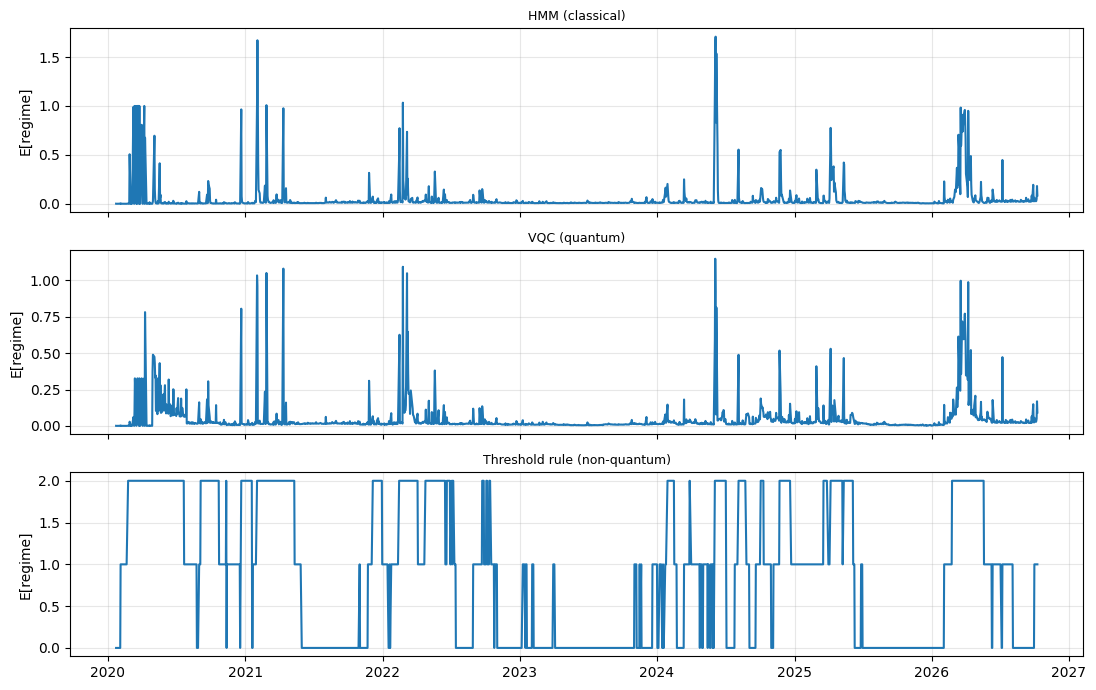

In [21]:
# cross-check the fast simulator against a Qiskit circuit
rng = np.random.default_rng(0); th_t = init_params(rng); Xt = np.clip(rng.normal(size=(4, 3)), -3, 3)
print("VQC numpy vs Qiskit, max |diff| in <Z>:", np.abs(vqc_expZ(th_t, Xt) - np.array([vqc_qiskit_expZ(th_t, x) for x in Xt])).max())

t0 = time.time(); _VQC_STATE["th"] = None
panels_vqc = build_panels(vqc_panel); print(f"VQC panels built in {time.time()-t0:.0f}s")
named = {"HMM (classical)": panels_hmm, "VQC (quantum)": panels_vqc, "Threshold rule (non-quantum)": panels_thr}
tab7_reg = regime_report(named); display(tab7_reg)

rs7 = [run_backtest(pn, solver_brute, "Regimes: " + nm + " (brute force)") for nm, pn in named.items()]
tab7_fin = summarize(rs7, bench); display(tab7_fin)

fig, axs = plt.subplots(len(named), 1, figsize=(11, 2 * len(named) + 1), sharex=True)
for ax, (name, pan) in zip(axs, named.items()):
    P = oos_probs(pan); ax.plot(P.index, P.to_numpy() @ np.arange(3)); ax.set_ylabel("E[regime]"); ax.set_title(name, fontsize=9); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### A second quantum regime model with an independent target
The first VQC distils the HMM's own posteriors, so it cannot be claimed to beat the HMM. This variant is trained on **next-10-day realised-volatility terciles**, which the HMM never sees.

In [22]:
# ---- second quantum regime model: VQC trained on an INDEPENDENT target (next-10-day realised volatility terciles) ----
# The first VQC distils the HMM; this one does not see the HMM at all, so it can genuinely disagree with it.
if CFG["vqc_rv"]:
    t0 = time.time(); TARGET = "realized_vol"; _VQC_STATE["th"] = None
    panels_vqc_rv = build_panels(vqc_panel); TARGET = "hmm_soft"; print(f"VQC (realised-vol target) panels built in {time.time()-t0:.0f}s")
    named["VQC (quantum, realised-vol target)"] = panels_vqc_rv
    tab7_reg = regime_report(named); display(tab7_reg)
    rs7.append(run_backtest(panels_vqc_rv, solver_brute, "Regimes: VQC (quantum, realised-vol target) (brute force)"))
    tab7_fin = summarize(rs7, bench); display(tab7_fin)


VQC (realised-vol target) panels built in 206s


,Argmax agreement w/ HMM,Mean |dP| vs HMM,Switch rate (stability),"Spearman(E[regime], fwd vol)",Fwd vol | Low/Med/High
Regime source,,,,,
HMM (classical),1.000,0.000,0.026,0.102,0.0086 / 0.0243 / 0.0078
VQC (quantum),0.987,0.024,0.017,0.274,0.0089 / 0.0123 / nan
Threshold rule (non-quantum),0.423,0.575,0.070,0.509,0.0066 / 0.0089 / 0.0121
"VQC (quantum, realised-vol target)",0.435,0.630,0.196,0.361,0.0073 / 0.0093 / 0.0112


,Sharpe,AnnReturn,MaxDD,TrackErr,AvgTurnover
Strategy,,,,,
Regimes: HMM (classical) (brute force),0.724,0.1228,-0.290,0.0781,0.173
Regimes: VQC (quantum) (brute force),0.771,0.1333,-0.292,0.0777,0.168
Regimes: Threshold rule (non-quantum) (brute force),0.679,0.1081,-0.284,0.0719,0.542
"Regimes: VQC (quantum, realised-vol target) (brute force)",0.649,0.1021,-0.277,0.0793,0.152
Equal-weight 1/N (all 11),1.003,0.1683,-0.327,0.0000,0.000


## 8. Statistics: benchmarks, block-bootstrap confidence intervals, agreement with the exact optimum
Daily-return Sharpe ratios of 3-6 months of a 1,600-day sample are noisy. All Sharpe comparisons below use a **21-day moving-block bootstrap** (paired across strategies) so differences are only called real when the confidence interval excludes zero.

In [23]:
# ======================= SECTION 8: STATISTICS - benchmarks, block-bootstrap CIs, agreement with the exact optimum =======================
px_all = raw_prices[[c for c in raw_prices.columns if not c.startswith("^")]]
R_all = px_all.pct_change().reindex(returns_df.index)                       # simple returns of every downloaded stock
_start = sorted(panels_hmm)[0]
bench18 = dict(label="Equal-weight 1/N (all 18 downloaded stocks)", daily=R_all.mean(axis=1).iloc[_start + 1:], rebal=pd.DataFrame(dict(turnover=[0.0])))
benches = [bench, bench18]
if "^NSEI" in raw_prices.columns:
    idx_r = raw_prices["^NSEI"].pct_change().reindex(returns_df.index).iloc[_start + 1:]
    benches.append(dict(label="Nifty 50 index (buy & hold)", daily=idx_r, rebal=pd.DataFrame(dict(turnover=[0.0]))))
strategies = [bt_bf, bt_sa] + qaoa_res + rs7[1:]                           # rs7[0] duplicates bt_bf
all_series = strategies + benches

def _boot_idx(n, block, rng):
    nb = -(-n // block); st = rng.integers(0, n - block + 1, nb)
    return (st[:, None] + np.arange(block)).ravel()[:n]
def _sharpe_rows(X):
    s = X.std(axis=-1, ddof=1); return np.where(s > 0, X.mean(-1) / s * np.sqrt(252), np.nan)

def sharpe_table(results, ref, B=2000, block=21, seed=0):
    """Moving-block bootstrap (21-day blocks, paired across strategies). Sharpe = mean/std*sqrt(252) of NET daily returns, rf = 0."""
    D = pd.DataFrame({r["label"]: r["daily"] for r in results}).dropna(); refv = ref["daily"].reindex(D.index).to_numpy()
    n = len(D); rng = np.random.default_rng(seed); I = np.stack([_boot_idx(n, block, rng) for _ in range(B)])
    sh_ref = _sharpe_rows(refv[I]); rows = []
    for lab in D.columns:
        x = D[lab].to_numpy(); sh = _sharpe_rows(x[I]); d = sh - sh_ref
        p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
        rows.append(dict(Strategy=lab, Sharpe=round(float(_sharpe_rows(x[None])[0]), 3), CI95=f"[{np.nanpercentile(sh, 2.5):.2f}, {np.nanpercentile(sh, 97.5):.2f}]",
                         dSharpe_vs_EW11=round(float(_sharpe_rows(x[None])[0] - _sharpe_rows(refv[None])[0]), 3),
                         dCI95=f"[{np.nanpercentile(d, 2.5):.2f}, {np.nanpercentile(d, 97.5):.2f}]", p_value=round(p, 3)))
    return pd.DataFrame(rows).set_index("Strategy")

tab8_sharpe = sharpe_table(all_series, bench, B=CFG["boot"])
tab8_fin = summarize(strategies, bench); tab8_fin = pd.concat([tab8_fin, pd.DataFrame([metrics(b, bench["daily"]) for b in benches[1:]]).set_index("Strategy")])
tab8 = tab8_fin.join(tab8_sharpe[["CI95", "dSharpe_vs_EW11", "dCI95", "p_value"]], how="left"); display(tab8)

def agreement(res, ref):
    a = res["rebal"].set_index("date")["picked"]; b = ref["rebal"].set_index("date")["picked"]; d = a.index.intersection(b.index)
    return dict(same_set=round(float(np.mean([set(a[x]) == set(b[x]) for x in d])), 3), mean_overlap=round(float(np.mean([len(set(a[x]) & set(b[x])) / K for x in d])), 3))
tab8_agree = pd.DataFrame({r["label"]: agreement(r, bt_bf) for r in strategies if r is not bt_bf}).T
print("Agreement of each strategy's picks with the exact (brute-force) optimum on the same dates (path-dependent through the turnover term):"); display(tab8_agree)


,Sharpe,AnnReturn,MaxDD,TrackErr,AvgTurnover,CI95,dSharpe_vs_EW11,dCI95,p_value
Strategy,,,,,,,,,
HMM + Brute force,0.724,0.1228,-0.290,0.0781,0.173,"[0.04, 1.56]",-0.278,"[-0.70, 0.08]",0.127
HMM + Simulated annealing,0.724,0.1228,-0.290,0.0781,0.173,"[0.04, 1.56]",-0.278,"[-0.70, 0.08]",0.127
QAOA cold (1 start),0.698,0.1175,-0.290,0.0780,0.193,"[0.02, 1.54]",-0.305,"[-0.75, 0.06]",0.103
QAOA cold (3 starts),0.724,0.1228,-0.290,0.0781,0.173,"[0.04, 1.56]",-0.278,"[-0.70, 0.08]",0.127
QAOA warm: dominant regime,0.744,0.1274,-0.292,0.0778,0.158,"[0.06, 1.57]",-0.259,"[-0.69, 0.07]",0.133
QAOA warm: regime blend,0.740,0.1260,-0.292,0.0784,0.168,"[0.05, 1.57]",-0.262,"[-0.70, 0.08]",0.144
QAOA warm: previous date,0.724,0.1228,-0.290,0.0781,0.173,"[0.04, 1.56]",-0.278,"[-0.70, 0.08]",0.127
CONTROL warm: shuffled-regime library,0.724,0.1228,-0.290,0.0781,0.173,"[0.04, 1.56]",-0.278,"[-0.70, 0.08]",0.127
CONTROL warm: pooled (regime-agnostic) library,0.724,0.1228,-0.290,0.0781,0.173,"[0.04, 1.56]",-0.278,"[-0.70, 0.08]",0.127


Agreement of each strategy's picks with the exact (brute-force) optimum on the same dates (path-dependent through the turnover term):


,same_set,mean_overlap
HMM + Simulated annealing,1.000,1.000
QAOA cold (1 start),0.887,0.978
QAOA cold (3 starts),1.000,1.000
QAOA warm: dominant regime,0.975,0.995
QAOA warm: regime blend,0.988,0.997
QAOA warm: previous date,1.000,1.000
CONTROL warm: shuffled-regime library,1.000,1.000
CONTROL warm: pooled (regime-agnostic) library,1.000,1.000
Regimes: VQC (quantum) (brute force),0.688,0.922
Regimes: Threshold rule (non-quantum) (brute force),0.100,0.593


## 9. Robustness: one-at-a-time sensitivity (K, risk aversion, turnover cost)
The defaults were fixed *before* looking at results, so this is a fragility check, not a tuning search.

In [24]:
# ======================= SECTION 9: ROBUSTNESS - one-at-a-time sensitivity of the exact-optimum backtest =======================
import contextlib
@contextlib.contextmanager
def override(**kw):
    g = globals(); old = {k: g[k] for k in kw}; g.update(kw)
    try: yield
    finally: g.update(old)

_L0 = dict(LAMBDA_R)
sens_rows = []
if CFG["sens"]:
    grid = [("K", k, dict(K=k)) for k in (3, 4, 5, 6, 7)] + \
           [("lambda scale", s, dict(LAMBDA_R={r: v * s for r, v in _L0.items()})) for s in (0.5, 1.0, 2.0, 4.0)] + \
           [("kappa", kk, dict(KAPPA=kk)) for kk in (0.0, 0.002, 0.005, 0.01)]
    for pname, val, kw in grid:
        with override(**kw):
            res = run_backtest(panels_hmm, solver_brute, "x"); m = metrics(res, bench["daily"])
        sens_rows.append(dict(parameter=pname, value=val, Sharpe=m["Sharpe"], AnnReturn=m["AnnReturn"], MaxDD=m["MaxDD"], TrackErr=m["TrackErr"], AvgTurnover=m["AvgTurnover"]))
    tab9_sens = pd.DataFrame(sens_rows).set_index(["parameter", "value"])
    print("Defaults (K=5, lambda scale 1, kappa 0.002) were fixed in advance, NOT tuned. This table shows how fragile the result is, not a tuning search.")
    print(f"Equal-weight 1/N Sharpe for reference: {metrics(bench, bench['daily'])['Sharpe']}"); display(tab9_sens)
else:
    tab9_sens = pd.DataFrame(); print("FAST mode: sensitivity sweep skipped (runs in FULL).")


Defaults (K=5, lambda scale 1, kappa 0.002) were fixed in advance, NOT tuned. This table shows how fragile the result is, not a tuning search.
Equal-weight 1/N Sharpe for reference: 1.003


Sharpe  AnnReturn  MaxDD  TrackErr  AvgTurnover
parameter    value                                                 
K            3.000   0.583     0.1014 -0.282    0.1143        0.246
             4.000   0.612     0.1030 -0.303    0.0925        0.200
             5.000   0.724     0.1228 -0.290    0.0781        0.173
             6.000   0.813     0.1384 -0.270    0.0662        0.117
             7.000   0.790     0.1328 -0.296    0.0534        0.098
lambda scale 0.500   0.716     0.1244 -0.292    0.0772        0.163
             1.000   0.724     0.1228 -0.290    0.0781        0.173
             2.000   0.677     0.1114 -0.290    0.0777        0.183
             4.000   0.669     0.1078 -0.275    0.0774        0.183
kappa        0.000   0.691     0.1157 -0.290    0.0785        0.262
             0.002   0.724     0.1228 -0.290    0.0781        0.173
             0.005   0.698     0.1165 -0.290    0.0785        0.132
             0.010   0.538     0.0849 -0.275    0.0794        0.098

## 10. Scaling and sampling budget (RQ4, simulation only)
**Scope:** real hardware and device-noise models are out of scope. This section covers (a) computational scaling of classical search vs exact quantum-circuit simulation and (b) finite-shot sampling, which is the part of the hardware story we can measure honestly on a simulator.

In [25]:
# ======================= SECTION 10a: COMPUTATIONAL SCALING (classical vs simulated-QAOA cost as N grows) =======================
order = SELECTED_UNIVERSE + [c for c in px_all.columns if c not in SELECTED_UNIVERSE]
def scaling_study(Ns, lam=3.0):
    rows = []
    for n in Ns:
        k = max(2, int(round(0.45 * n)))
        Rr = R_all[order[:n]].iloc[-504:]; mu, Sg = Rr.mean().to_numpy() * 252, Rr.cov().to_numpy() * 252
        with override(N=n, K=k):
            obj = build_objective(mu, Sg, lam, k, KAPPA, np.zeros(n))
            t = time.time(); bf_ = brute_force(obj, n, k); t_bf = time.time() - t
            t = time.time(); sa_ = simulated_annealing(obj, n, k, n_iter=3000, seed=0); t_sa = time.time() - t
            t = time.time(); inst = Instance(obj); t_inst = time.time() - t
            th = np.array([0.4, 0.4, 0.3, 0.3]); t = time.time()
            for _ in range(3): qaoa_probs(th, 2, inst, "xy")
            t_eval = (time.time() - t) / 3
            tq = transpile(dicke_circuit(n, k), basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=0)
            rows.append({"N": n, "K": k, "feasible subsets C(N,K)": math.comb(n, k), "full state dim 2^N": 2 ** n, "state memory (MB)": round(16 * 2 ** n / 2**20, 2),
                         "brute force (s)": round(t_bf, 4), "SA 3000 it (s)": round(t_sa, 3), "SA hit optimum": bool(np.isclose(sa_["cost"], bf_["cost"])),
                         "QAOA build (s)": round(t_inst, 3), "QAOA 1 eval p=2 (s)": round(t_eval, 4), "Dicke prep CX": tq.count_ops().get("cx", 0)})
    return pd.DataFrame(rows).set_index("N")
import math
tab10_scale = scaling_study(CFG["scale_Ns"]); display(tab10_scale)
print("A full QAOA run needs ~150-600 evaluations per restart, so simulated-QAOA wall time ~ 200 x 'QAOA 1 eval'. Brute force stays cheap far beyond what a state-vector simulator can reach, "
      "and only the Hamming-weight-K subspace (dimension C(N,K)) is ever populated: a natural route to larger N.")


,K,"feasible subsets C(N,K)",full state dim 2^N,state memory (MB),brute force (s),SA 3000 it (s),SA hit optimum,QAOA build (s),QAOA 1 eval p=2 (s),Dicke prep CX
N,,,,,,,,,,
8,4,70,256,0.00,0.0001,0.077,True,0.013,0.0003,178
10,4,210,1024,0.02,0.0002,0.077,True,0.014,0.0003,246
12,5,792,4096,0.06,0.0005,0.076,True,0.019,0.0008,384
14,6,3003,16384,0.25,0.0023,0.077,True,0.027,0.0026,552
16,7,11440,65536,1.00,0.0109,0.079,True,0.079,0.0152,750
18,8,43758,262144,4.00,0.0519,0.105,True,0.355,0.0958,978


A full QAOA run needs ~150-600 evaluations per restart, so simulated-QAOA wall time ~ 200 x 'QAOA 1 eval'. Brute force stays cheap far beyond what a state-vector simulator can reach, and only the Hamming-weight-K subspace (dimension C(N,K)) is ever populated: a natural route to larger N.


In [26]:
# ======================= SECTION 10b: SAMPLING-BUDGET STUDY ("Phase 8-lite": shot noise only, NO device noise, NO hardware) =======================
def shot_study(n_inst, shots_list=(16, 64, 256, 1024, 4096), trials=200):
    rows = []; insts = sample_instances(n_inst); ARb_cache = {}
    for (i, inst, ctx) in insts:
        r = run_qaoa(inst, "xy", P_DEPTH, ALPHA, restarts=3, seed=i); pr = qaoa_probs(r["theta"], P_DEPTH, inst, "xy")
        AR_b = inst.AR(inst.E_xy); idx = np.flatnonzero(inst.feas); rng = np.random.default_rng(i)
        for S in shots_list:
            q_ar, q_hit, r_ar, r_hit = [], [], [], []
            for _ in range(trials):
                s = rng.choice(2 ** N, size=S, p=pr); s = s[inst.feas[s]]; q_ar.append(AR_b[s].max() if len(s) else 0.0); q_hit.append(inst.opt in set(s.tolist()))
                s2 = rng.choice(idx, size=S); r_ar.append(AR_b[s2].max()); r_hit.append(inst.opt in set(s2.tolist()))
            rows.append(dict(instance=i, shots=S, qaoa_bestAR=np.mean(q_ar), random_bestAR=np.mean(r_ar), qaoa_P_opt=np.mean(q_hit), random_P_opt=np.mean(r_hit)))
    return pd.DataFrame(rows)
shot_raw = shot_study(CFG["shot_inst"])
tab10_shots = shot_raw.groupby("shots")[["qaoa_bestAR", "random_bestAR", "qaoa_P_opt", "random_P_opt"]].mean().round(3)
tab10_shots["P_opt lift (x)"] = (tab10_shots["qaoa_P_opt"] / tab10_shots["random_P_opt"]).round(2)
print("Best-of-S sampled approximation ratio and probability of seeing the exact optimum within S shots (QAOA trained noiselessly, then sampled) vs uniform feasible sampling:"); display(tab10_shots)

# training with a noisy (finite-shot) objective
noisy_rows = []
for (i, inst, ctx) in sample_instances(CFG["shot_inst"]):
    for s in (None, 1024, 256, 64):
        r = run_qaoa(inst, "xy", P_DEPTH, ALPHA, restarts=2, seed=i, shots=s); m = evaluate(inst, r["theta"], P_DEPTH, "xy", seed=i)
        noisy_rows.append(dict(instance=i, training_shots=str(s or "exact"), exp_AR=m["exp_AR"], p_opt=m["p_opt"]))
tab10_noisy = pd.DataFrame(noisy_rows).groupby("training_shots")[["exp_AR", "p_opt"]].mean().round(4).loc[["exact", "1024", "256", "64"]]
print("Final solution quality (exact evaluation) when the optimiser only sees S-shot estimates of CVaR:"); display(tab10_noisy)

# classical heuristic under a comparable evaluation budget
bud_rows = []
for (i, inst, ctx) in sample_instances(CFG["shot_inst"]):
    allc = brute_force(inst.obj, N, K)["all_costs"]
    for it in (100, 500, 3000):
        res = [simulated_annealing(inst.obj, N, K, n_iter=it, seed=s) for s in range(10)]
        bud_rows.append(dict(budget=it, AR=np.mean([approx_ratio(r["cost"], allc) for r in res]), hit=np.mean([np.isclose(r["cost"], allc.min()) for r in res])))
tab10_sa = pd.DataFrame(bud_rows).groupby("budget").mean().round(3); tab10_sa.columns = ["SA mean AR", "SA hit-optimum rate"]
print("Simulated annealing at fixed cost-evaluation budgets (for comparison with QAOA ~150-600 evaluations x shots):"); display(tab10_sa)


Best-of-S sampled approximation ratio and probability of seeing the exact optimum within S shots (QAOA trained noiselessly, then sampled) vs uniform feasible sampling:


,qaoa_bestAR,random_bestAR,qaoa_P_opt,random_P_opt,P_opt lift (x)
shots,,,,,
16,0.961,0.840,0.431,0.022,19.59
64,0.994,0.922,0.847,0.130,6.52
256,1.000,0.976,0.999,0.456,2.19
1024,1.000,0.997,1.000,0.896,1.12
4096,1.000,1.000,1.000,1.000,1.00


Final solution quality (exact evaluation) when the optimiser only sees S-shot estimates of CVaR:


,exp_AR,p_opt
training_shots,,
exact,0.6553,0.0212
1024,0.6105,0.0117
256,0.5238,0.0072
64,0.5203,0.0058


Simulated annealing at fixed cost-evaluation budgets (for comparison with QAOA ~150-600 evaluations x shots):


,SA mean AR,SA hit-optimum rate
budget,,
100,0.999,0.925
500,1.000,1.000
3000,1.000,1.000


## 11. Live dashboard: today's picks
The software's actual output: given all data up to the latest close, infer the regime, build the posterior-blended objective, and let the regime-warm-started CVaR-QAOA choose K = 5 stocks (checked against the exact optimum and simulated annealing).

In [27]:
# ======================= SECTION 11: TODAY'S PICKS (the decision the software would make right now) =======================
def recommend_today(n_restarts_lib=None):
    n = len(returns_df); i = n - 1; asof = returns_df.index[i]
    panel_now = hmm_panel(n, n)                                        # HMM trained on ALL history; filtered posteriors through today
    df_p = returns_df[stocks].join(panel_now, how="inner")
    held = [r for r in qaoa_res if r["label"] == "QAOA warm: regime blend"] or [bt_bf]
    x_prev = np.zeros(N); x_prev[list(held[0]["rebal"]["picked"].iloc[-1])] = 1       # holdings after the last backtest rebalance
    obj, ctx = make_objective_at(df_p, i, x_prev); ctx.update(i=i, refit=n)
    libN = build_library({n: panel_now}, restarts=n_restarts_lib or CFG["lib_restarts"])
    inst = Instance(obj); start = sum(ctx["p"][r] * libN[n][r] for r in range(3))
    q = run_qaoa(inst, "xy", P_DEPTH, ALPHA, init=[start], maxiter=200, seed=i)
    probs = qaoa_probs(q["theta"], P_DEPTH, inst, "xy"); xq = select_from_samples(inst, q["theta"], P_DEPTH, "xy", shots=1024, seed=i)
    xb = brute_force(obj, N, K); xs = simulated_annealing(obj, N, K, n_iter=3000, seed=i)
    top = np.argsort(-probs)[:5]
    return dict(asof=asof, p=ctx["p"], lam=ctx["lam"], mu=ctx["mu"], Sigma=ctx["Sigma"], x_prev=x_prev, xq=xq, xb=xb["x"], xs=xs["x"],
                cost_q=float(obj["cost"](xq)), cost_b=float(xb["cost"]), cost_s=float(xs["cost"]), AR_q=float(approx_ratio(obj["cost"](xq), xb["all_costs"])),
                p_opt=float(probs[inst.opt]), top=[(inst.bitstring(int(b)), float(probs[b]), float(obj["cost"](inst.bitstring(int(b))))) for b in top], theta=q["theta"], panel=panel_now)

t0 = time.time(); rec = recommend_today(); print(f"computed in {time.time()-t0:.0f}s")
short = [s.replace(".NS", "") for s in stocks]
picks = pd.DataFrame({"Stock": short, "QAOA pick": rec["xq"].astype(int), "Exact (brute force)": rec["xb"].astype(int), "Simulated annealing": rec["xs"].astype(int),
                      "Held at last rebalance": rec["x_prev"].astype(int), "Exp. return (ann.)": rec["mu"].round(3), "Vol (ann.)": np.sqrt(np.diag(rec["Sigma"])).round(3)}).set_index("Stock")
reg_names = ["Low-vol", "Medium-vol", "High-vol"]
print(f"As of {rec['asof'].date()}  |  regime posterior: " + ", ".join(f"{n} {p:.0%}" for n, p in zip(reg_names, rec["p"])) + f"  |  blended risk aversion lambda_t = {rec['lam']:.2f}")
display(picks[picks[["QAOA pick", "Exact (brute force)", "Simulated annealing", "Held at last rebalance"]].sum(axis=1) > 0])
buys = [s for s, a, b in zip(short, rec["xq"], rec["x_prev"]) if a == 1 and b == 0]; sells = [s for s, a, b in zip(short, rec["xq"], rec["x_prev"]) if a == 0 and b == 1]
print(f"QAOA portfolio (equal weight {1/K:.0%} each): {[s for s, a in zip(short, rec['xq']) if a == 1]}  |  buys: {buys or 'none'}  sells: {sells or 'none'}")
print(f"QAOA == exact optimum: {bool((rec['xq'] == rec['xb']).all())} | approximation ratio {rec['AR_q']:.3f} | P(optimum) under final QAOA state {rec['p_opt']:.1%} (random feasible: {1/math.comb(N, K):.2%})")
print("Research prototype on a frozen 11-stock universe. Not investment advice.")


computed in 4s
As of 2026-10-09  |  regime posterior: Low-vol 81%, Medium-vol 18%, High-vol 1%  |  blended risk aversion lambda_t = 1.43


,QAOA pick,Exact (brute force),Simulated annealing,Held at last rebalance,Exp. return (ann.),Vol (ann.)
Stock,,,,,,
LT,1,1,1,1,0.181,0.267
SBIN,0,0,0,1,0.180,0.309
BHARTIARTL,1,1,1,1,0.189,0.288
M&M,1,1,1,1,0.222,0.315
SUNPHARMA,1,1,1,0,0.170,0.267
POWERGRID,1,1,1,1,0.177,0.259


QAOA portfolio (equal weight 20% each): ['LT', 'BHARTIARTL', 'M&M', 'SUNPHARMA', 'POWERGRID']  |  buys: ['SUNPHARMA']  sells: ['SBIN']
QAOA == exact optimum: True | approximation ratio 1.000 | P(optimum) under final QAOA state 3.5% (random feasible: 0.22%)
Research prototype on a frozen 11-stock universe. Not investment advice.


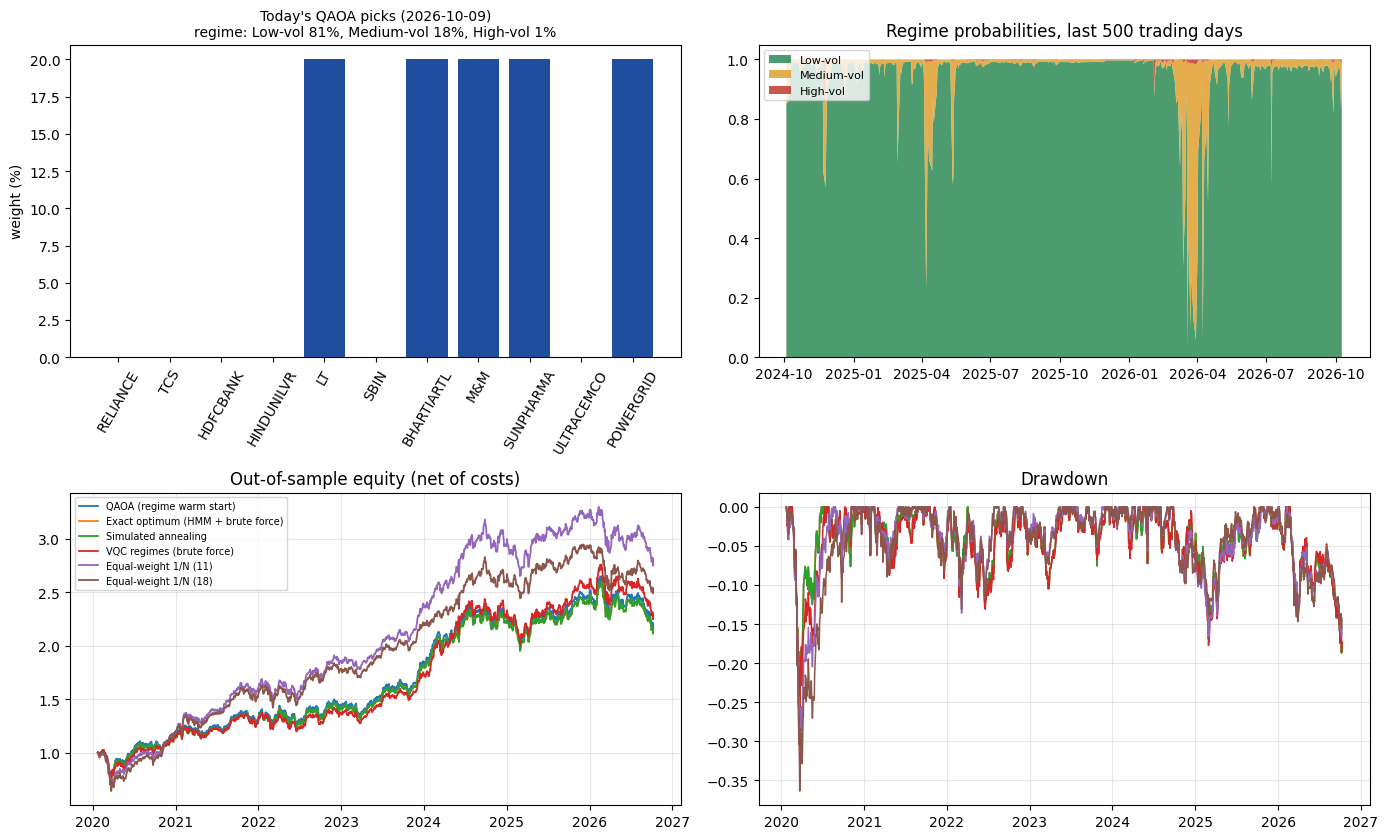

In [28]:
# ======================= SECTION 11: LIVE DASHBOARD =======================
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display
qkey = next((r for r in qaoa_res if r["label"] == "QAOA warm: regime blend"), qaoa_res[-1])
show = {"QAOA (regime warm start)": qkey, "Exact optimum (HMM + brute force)": bt_bf, "Simulated annealing": bt_sa, "VQC regimes (brute force)": rs7[1],
        "Equal-weight 1/N (11)": bench, "Equal-weight 1/N (18)": bench18}
curves = {k: (1 + v["daily"]).cumprod() for k, v in show.items()}
P_oos = oos_probs(panels_hmm)

# ---- headline cards ----
sel = [s for s, a in zip(short, rec["xq"]) if a == 1]; top_reg = reg_names[int(np.argmax(rec["p"]))]
cards = "".join(f"<div style='flex:1;min-width:150px;background:#f4f6fb;border-radius:10px;padding:10px 14px;margin:4px'><div style='font-size:12px;color:#667'>{a}</div><div style='font-size:20px;font-weight:600;color:#1a2540'>{b}</div></div>" for a, b in [
    ("As of", str(rec["asof"].date())), ("Current regime", f"{top_reg} ({rec['p'].max():.0%})"), ("Risk aversion lambda", f"{rec['lam']:.2f}"),
    ("QAOA picks (equal weight)", ", ".join(sel)), ("Matches exact optimum", "yes" if (rec["xq"] == rec["xb"]).all() else f"no (AR {rec['AR_q']:.3f})"),
    ("Out-of-sample Sharpe (QAOA)", f"{metrics(qkey, bench['daily'])['Sharpe']}  vs EW {metrics(bench, bench['daily'])['Sharpe']}")])
display(HTML(f"<div style='display:flex;flex-wrap:wrap;font-family:sans-serif'>{cards}</div>"))

# ---- interactive Plotly dashboard ----
fig = make_subplots(rows=4, cols=1, row_heights=[0.22, 0.30, 0.20, 0.28], vertical_spacing=0.06, specs=[[{"type": "table"}], [{}], [{}], [{}]],
                    subplot_titles=("", "Out-of-sample equity (net of 10 bps costs)", "Drawdown", "Filtered HMM regime probabilities (no look-ahead)"))
tb = picks[picks[["QAOA pick", "Exact (brute force)"]].sum(axis=1) > 0].reset_index()
fig.add_trace(go.Table(header=dict(values=["Stock", "QAOA", "Exact", "SA", "Held", "Exp. ret", "Vol"], fill_color="#1a2540", font=dict(color="white")),
                       cells=dict(values=[tb["Stock"], tb["QAOA pick"], tb["Exact (brute force)"], tb["Simulated annealing"], tb["Held at last rebalance"], tb["Exp. return (ann.)"], tb["Vol (ann.)"]], fill_color="#f4f6fb")), row=1, col=1)
for k, c in curves.items():
    fig.add_trace(go.Scatter(x=c.index, y=c.values, name=k, mode="lines"), row=2, col=1)
    fig.add_trace(go.Scatter(x=c.index, y=(c / c.cummax() - 1).values, name=k, mode="lines", showlegend=False), row=3, col=1)
for r, (nm, col) in enumerate(zip(reg_names, ["#2e8b57", "#e0a030", "#c0392b"])):
    fig.add_trace(go.Scatter(x=P_oos.index, y=P_oos.iloc[:, r], name=nm, stackgroup="reg", line=dict(width=0.5, color=col)), row=4, col=1)
fig.update_layout(height=1100, title=f"Regime-conditioned CVaR-QAOA portfolio | as of {rec['asof'].date()}", template="plotly_white", legend=dict(orientation="h", y=-0.05))
fig.write_html("results/dashboard.html", include_plotlyjs="cdn"); fig.show()

# ---- static dashboard (renders everywhere, also saved as PNG for the reports) ----
import matplotlib.pyplot as plt
fig2, axs = plt.subplots(2, 2, figsize=(14, 8.5))
ax = axs[0, 0]; cols = ["#1f4e9e" if a == 1 else "#c9ced8" for a in rec["xq"]]
ax.bar(short, np.where(rec["xq"] == 1, 1 / K, 0.0) * 100, color=cols); ax.set_ylabel("weight (%)"); ax.tick_params(axis="x", rotation=60)
ax.set_title(f"Today's QAOA picks ({rec['asof'].date()})\nregime: " + ", ".join(f"{n} {p:.0%}" for n, p in zip(reg_names, rec["p"])), fontsize=10)
ax = axs[0, 1]; Pn = P_oos.iloc[-500:]; ax.stackplot(Pn.index, Pn.T.values, labels=reg_names, colors=["#2e8b57", "#e0a030", "#c0392b"], alpha=.85); ax.set_title("Regime probabilities, last 500 trading days"); ax.legend(loc="upper left", fontsize=8)
ax = axs[1, 0]
for k, c in curves.items(): ax.plot(c.index, c.values, label=k, lw=1.3)
ax.set_title("Out-of-sample equity (net of costs)"); ax.legend(fontsize=7); ax.grid(alpha=.3)
ax = axs[1, 1]
for k, c in curves.items(): ax.plot(c.index, c / c.cummax() - 1, label=k, lw=1.1)
ax.set_title("Drawdown"); ax.grid(alpha=.3)
plt.tight_layout(); fig2.savefig("results/figs/dashboard.png", dpi=130); plt.show()

# ---- replay any past rebalance ----
try:
    import ipywidgets as W
    rq = qkey["rebal"].set_index("date"); dd = W.Dropdown(options=[str(d.date()) for d in rq.index], value=str(rq.index[-1].date()), description="Rebalance")
    out = W.Output()
    def _show(_=None):
        with out:
            out.clear_output(); d = pd.Timestamp(dd.value); pk = [short[j] for j in rq.loc[d, "picked"]]; pr = P_oos.loc[d].to_numpy()
            print(f"{d.date()}  picks: {pk}  | turnover {rq.loc[d, 'turnover']:.2f} | regime: " + ", ".join(f"{n} {p:.0%}" for n, p in zip(reg_names, pr)))
    dd.observe(_show, names="value"); _show(); display(W.VBox([W.HTML("<b>Replay a past decision</b>"), dd, out]))
except Exception as e:
    print("(widget replay unavailable:", e, ")")


## 12. Save results and generate the Simulation Report (PDF)
Writes `results/*.csv`, `results/figs/*.png`, `results/dashboard.html`, `results/config_used.json` and **`results/Simulation_Report.pdf`**, whose conclusions are generated from this run's numbers.

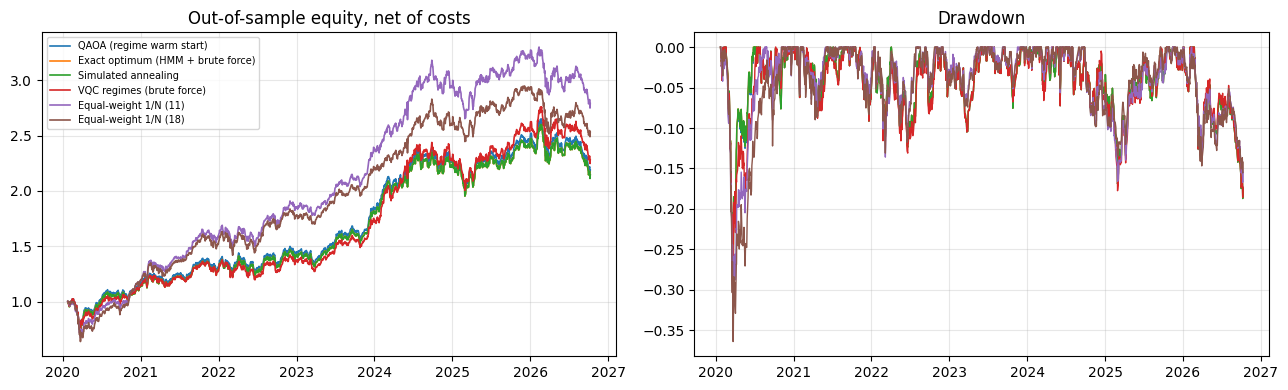

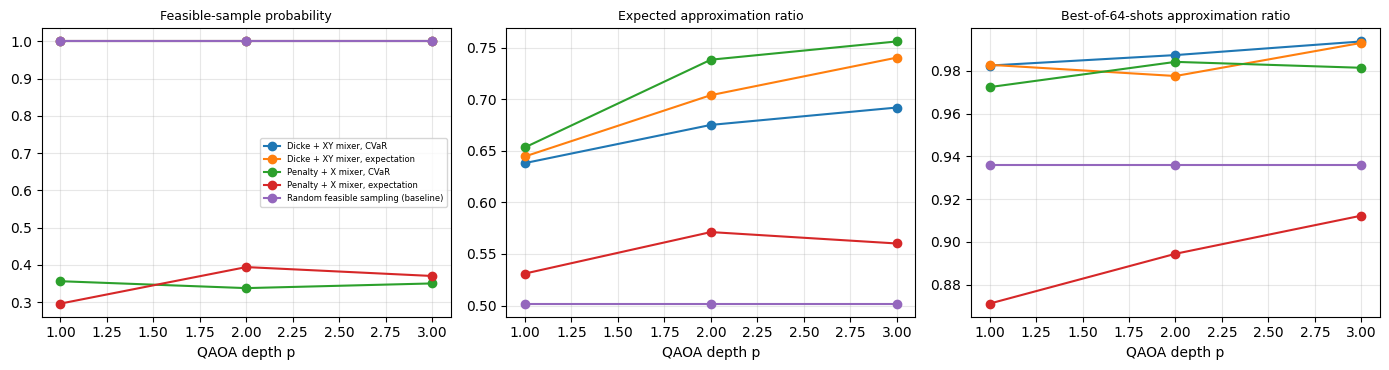

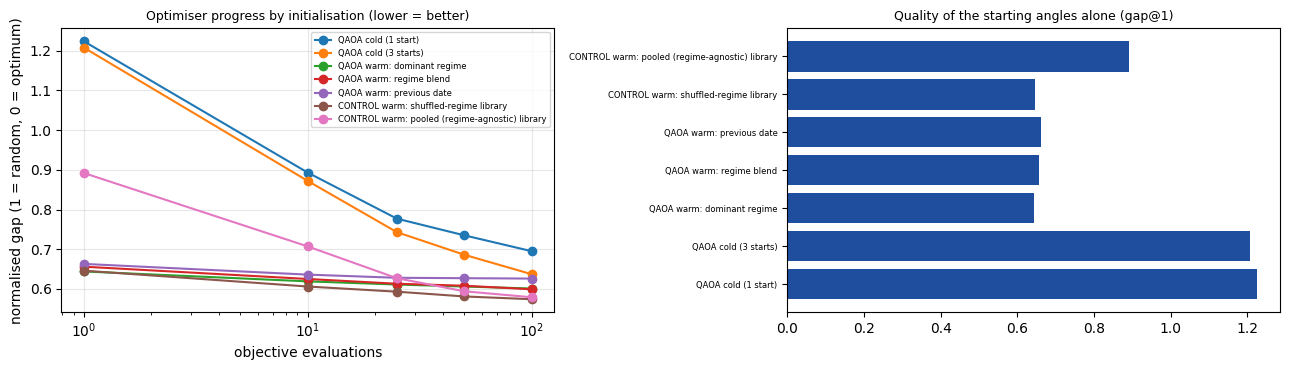

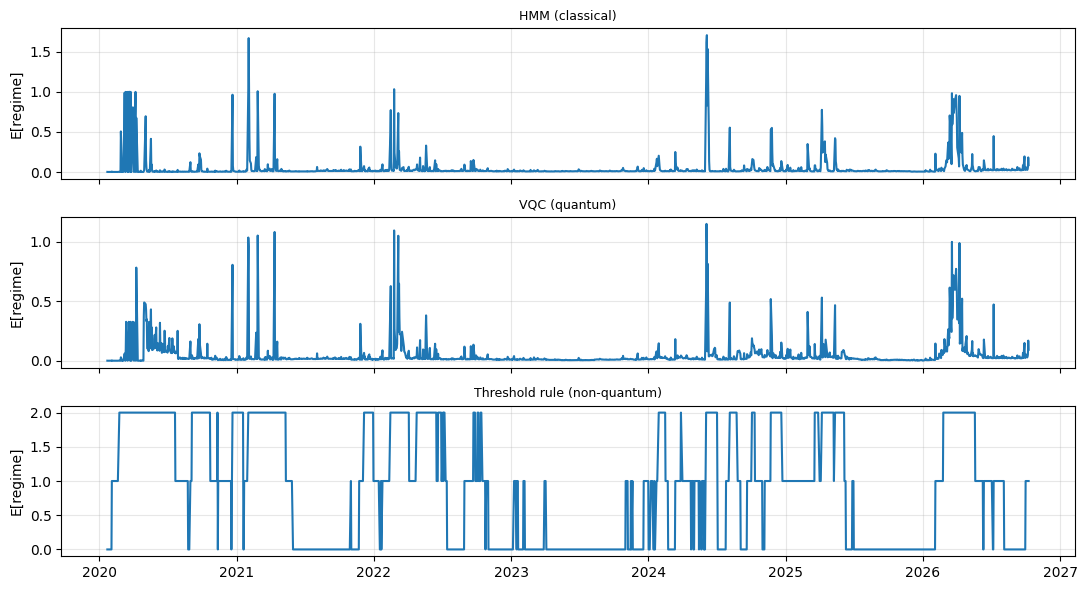

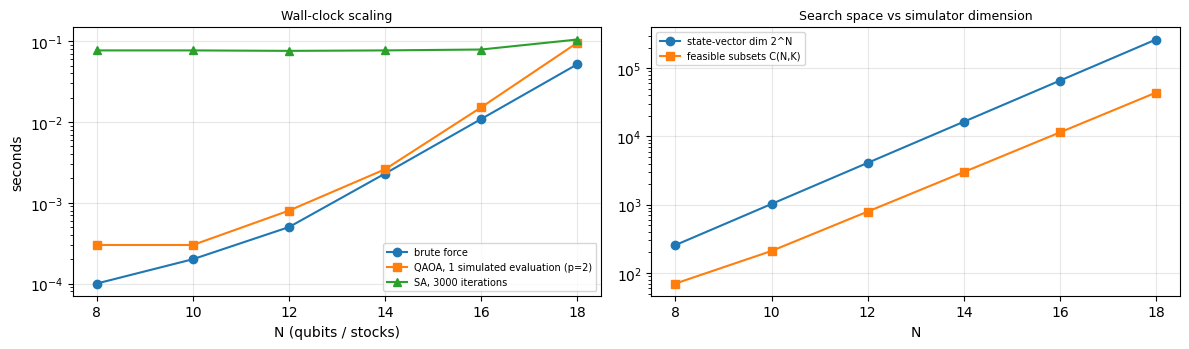

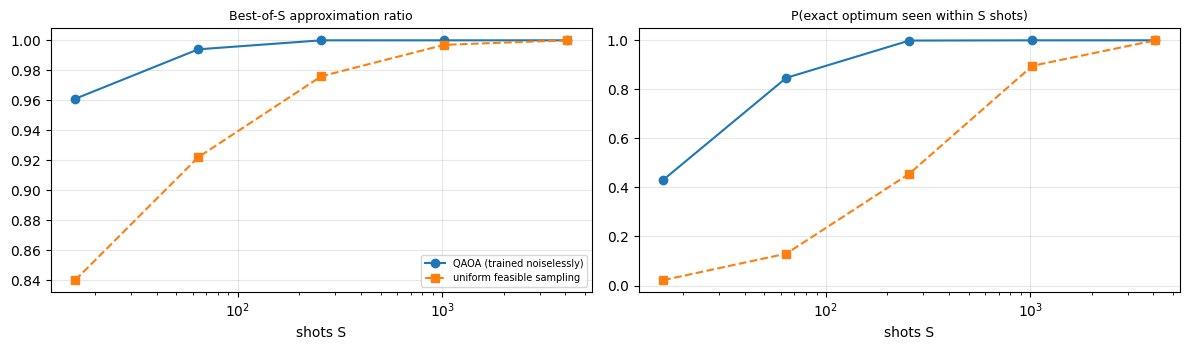

Wrote results/Simulation_Report.pdf, results/*.csv, results/figs/*.png, results/dashboard.html, results/config_used.json
- Constraint handling (RQ2): Dicke+XY samples were feasible 100% of the time at p=3, versus 35% for penalty+X mixer (CVaR) and 37% (expectation).
- Solution quality (RQ2, p=3): expected approximation ratio 0.692 (XY, CVaR) vs 0.741 (XY, expectation) vs 0.756 (penalty, CVaR); probability of the exact optimum 0.028 vs 0.0022 for uniform feasible sampling (lift 13.1x).
- Against random feasible sampling with the same 64 shots, the best-of-shots approximation ratio differs by +0.058 (0.994 vs 0.936): the QAOA sampler is ahead at this budget, but with only C(N,K) = 462 candidate subsets a classical search enumerates every candidate exactly, so this is not a practical advantage.
- Warm starts (RQ3): regime-blended library angles start at a normalised optimality gap of 0.66 (random cold start 1.22; 1 = random feasible subset, 0 = exact optimum) and sit at 0.61 vs 0.78 after

In [29]:
# ======================= SECTION 12: SAVE EVERYTHING + AUTO-GENERATED SIMULATION REPORT (PDF) =======================
import os, json, datetime
os.makedirs("results/figs", exist_ok=True)

# ---- figures used by the reports ----
def _save(name): plt.tight_layout(); plt.savefig(f"results/figs/{name}.png", dpi=130); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, c in curves.items(): ax[0].plot(c.index, c.values, label=k, lw=1.2); ax[1].plot(c.index, c / c.cummax() - 1, lw=1)
ax[0].set_title("Out-of-sample equity, net of costs"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3); ax[1].set_title("Drawdown"); ax[1].grid(alpha=.3); _save("equity")

g = rq2.groupby(["config", "p"])[["feasible_prob", "p_opt", "exp_AR", "best_of_shots_AR"]].mean().reset_index()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for cfgname, d in g.groupby("config"):
    for a, col, t in zip(ax, ["feasible_prob", "exp_AR", "best_of_shots_AR"], ["Feasible-sample probability", "Expected approximation ratio", "Best-of-64-shots approximation ratio"]):
        a.plot(d["p"], d[col], marker="o", label=cfgname); a.set_title(t, fontsize=9); a.set_xlabel("QAOA depth p"); a.grid(alpha=.3)
ax[0].legend(fontsize=6); _save("rq2")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for nm, row in tab6_eff.iterrows(): ax[0].plot([1, 10, 25, 50, 100], [row["gap@1 (start angles)"], row["gap@10"], row["gap@25"], row["gap@50"], row["gap@100"]], marker="o", label=nm)
ax[0].set_xscale("log"); ax[0].set_xlabel("objective evaluations"); ax[0].set_ylabel("normalised gap (1 = random, 0 = optimum)"); ax[0].set_title("Optimiser progress by initialisation (lower = better)", fontsize=9); ax[0].legend(fontsize=6); ax[0].grid(alpha=.3)
ax[1].barh(tab6_eff.index, tab6_eff["gap@1 (start angles)"], color="#1f4e9e"); ax[1].set_title("Quality of the starting angles alone (gap@1)", fontsize=9); ax[1].tick_params(axis="y", labelsize=6); _save("rq3")

fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for a, (nm, pn) in zip(ax, list(named.items())[:3]):
    P = oos_probs(pn); a.plot(P.index, P.to_numpy() @ np.arange(3)); a.set_ylabel("E[regime]"); a.set_title(nm, fontsize=9); a.grid(alpha=.3)
_save("regimes")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].semilogy(tab10_scale.index, tab10_scale["brute force (s)"], "o-", label="brute force"); ax[0].semilogy(tab10_scale.index, tab10_scale["QAOA 1 eval p=2 (s)"], "s-", label="QAOA, 1 simulated evaluation (p=2)")
ax[0].semilogy(tab10_scale.index, tab10_scale["SA 3000 it (s)"], "^-", label="SA, 3000 iterations"); ax[0].set_xlabel("N (qubits / stocks)"); ax[0].set_ylabel("seconds"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3); ax[0].set_title("Wall-clock scaling", fontsize=9)
ax[1].semilogy(tab10_scale.index, tab10_scale["full state dim 2^N"], "o-", label="state-vector dim 2^N"); ax[1].semilogy(tab10_scale.index, tab10_scale["feasible subsets C(N,K)"], "s-", label="feasible subsets C(N,K)")
ax[1].set_xlabel("N"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3); ax[1].set_title("Search space vs simulator dimension", fontsize=9); _save("scaling")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(tab10_shots.index, tab10_shots["qaoa_bestAR"], "o-", label="QAOA (trained noiselessly)"); ax[0].plot(tab10_shots.index, tab10_shots["random_bestAR"], "s--", label="uniform feasible sampling"); ax[0].set_xscale("log"); ax[0].set_xlabel("shots S"); ax[0].set_title("Best-of-S approximation ratio", fontsize=9); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].plot(tab10_shots.index, tab10_shots["qaoa_P_opt"], "o-"); ax[1].plot(tab10_shots.index, tab10_shots["random_P_opt"], "s--"); ax[1].set_xscale("log"); ax[1].set_xlabel("shots S"); ax[1].set_title("P(exact optimum seen within S shots)", fontsize=9); ax[1].grid(alpha=.3); _save("shots")

# ---- tables to disk ----
tables = {"phase3_classical": tab3, "phase5_rq2_summary": tab5, "phase5_circuit_resources": tab5_res, "phase6_optimizer": tab6_diag, "phase6_efficiency": tab6_eff,
          "phase6_financial": tab6_fin, "phase7_regime_quality": tab7_reg, "phase7_financial": tab7_fin, "stats_financial_with_ci": tab8, "stats_agreement_with_exact": tab8_agree,
          "robustness_sensitivity": tab9_sens, "scaling": tab10_scale, "shots_bestof": tab10_shots, "shots_noisy_training": tab10_noisy, "sa_budget": tab10_sa, "today_picks": picks}
for k, df in tables.items(): df.to_csv(f"results/{k}.csv")
rq2.to_csv("results/phase5_rq2_raw.csv", index=False)
pd.DataFrame({r["label"]: r["daily"] for r in all_series}).to_csv("results/daily_returns_all_strategies.csv")
cfg_used = dict(stocks=stocks, K=K, KAPPA=KAPPA, LAMBDA_R=LAMBDA_R, MIN_TRAIN=MIN_TRAIN, REFIT_EVERY=REFIT_EVERY, REBAL_EVERY=REBAL_EVERY, COST_BPS=COST_BPS, ALPHA=ALPHA,
                P_DEPTH=P_DEPTH, MODE=MODE, DATA_MODE=DATA_MODE, SEED=SEED, data_start=str(raw_prices.index.min().date()), data_end=str(raw_prices.index.max().date()),
                qiskit=qiskit.__version__, numpy=np.__version__, pandas=pd.__version__, generated=datetime.datetime.now().isoformat(timespec="seconds"))
json.dump(cfg_used, open("results/config_used.json", "w"), indent=2)

# ---- PDF helper ----
def build_pdf(path, title, blocks, subtitle=""):
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
    from reportlab.lib import colors
    from reportlab.lib.units import cm
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak, KeepTogether
    ss = getSampleStyleSheet(); body = ParagraphStyle("b", parent=ss["BodyText"], fontSize=9, leading=12.5)
    h1 = ParagraphStyle("h1", parent=ss["Heading1"], fontSize=15, textColor=colors.HexColor("#1a2540")); h2 = ParagraphStyle("h2", parent=ss["Heading2"], fontSize=11.5, textColor=colors.HexColor("#1f4e9e"))
    cell = ParagraphStyle("c", parent=body, fontSize=6.8, leading=8.4); W_ = A4[0] - 3.2 * cm
    esc = lambda x: str(x).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    doc = SimpleDocTemplate(path, pagesize=A4, leftMargin=1.6 * cm, rightMargin=1.6 * cm, topMargin=1.5 * cm, bottomMargin=1.5 * cm, title=title)
    story = [Paragraph(esc(title), ParagraphStyle("t", parent=ss["Title"], fontSize=20, textColor=colors.HexColor("#1a2540"))), Paragraph(esc(subtitle), body), Spacer(1, 10)]
    for kind, c in blocks:
        if kind == "h1": story.append(Paragraph(esc(c), h1))
        elif kind == "h2": story.append(Paragraph(esc(c), h2))
        elif kind == "p": story += [Paragraph(esc(c), body), Spacer(1, 5)]
        elif kind == "bullets": story += [Paragraph("&bull; " + esc(b), body) for b in c] + [Spacer(1, 5)]
        elif kind == "img":
            from PIL import Image as PI
            w, h = PI.open(c).size; story += [Image(c, width=W_, height=W_ * h / w), Spacer(1, 6)]
        elif kind == "pb": story.append(PageBreak())
        elif kind == "table":
            df = c.reset_index() if not isinstance(c.index, pd.RangeIndex) else c
            data = [[Paragraph(f"<b>{esc(x)}</b>", cell) for x in df.columns]] + [[Paragraph(esc(round(v, 4) if isinstance(v, float) else v), cell) for v in row] for row in df.to_numpy()]
            lens = [max(len(str(x)) for x in [df.columns[j]] + list(df.iloc[:, j])) for j in range(df.shape[1])]; ws = np.clip(np.array(lens, float), 5, 38); ws = ws / ws.sum() * W_
            t = Table(data, colWidths=list(ws), repeatRows=1)
            t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e6ebf5")), ("GRID", (0, 0), (-1, -1), 0.25, colors.HexColor("#b8c0d0")), ("VALIGN", (0, 0), (-1, -1), "TOP"),
                                   ("LEFTPADDING", (0, 0), (-1, -1), 2), ("RIGHTPADDING", (0, 0), (-1, -1), 2)]))
            story += [t, Spacer(1, 8)]
    doc.build(story)

# ---- numbers for the auto-conclusions ----
_fp = lambda p: "n/a" if p != p else ("<0.0001" if p < 1e-4 else f"{p:.4f}")
def _g(cfg, p, col):
    m = rq2[(rq2["config"] == cfg) & (rq2["p"] == p)][col]; return float(m.mean())
pmax = max(CFG["rq2_depths"]); pm = pmax
xyc, xye, pc, pe, rnd = "Dicke + XY mixer, CVaR", "Dicke + XY mixer, expectation", "Penalty + X mixer, CVaR", "Penalty + X mixer, expectation", "Random feasible sampling (baseline)"
conc = []
conc.append(f"Constraint handling (RQ2): Dicke+XY samples were feasible {_g(xyc, pm, 'feasible_prob'):.0%} of the time at p={pm}, versus {_g(pc, pm, 'feasible_prob'):.0%} for penalty+X mixer (CVaR) and {_g(pe, pm, 'feasible_prob'):.0%} (expectation).")
conc.append(f"Solution quality (RQ2, p={pm}): expected approximation ratio {_g(xyc, pm, 'exp_AR'):.3f} (XY, CVaR) vs {_g(xye, pm, 'exp_AR'):.3f} (XY, expectation) vs {_g(pc, pm, 'exp_AR'):.3f} (penalty, CVaR); probability of the exact optimum {_g(xyc, pm, 'p_opt'):.3f} vs {1/math.comb(N, K):.4f} for uniform feasible sampling (lift {_g(xyc, pm, 'p_opt')*math.comb(N, K):.1f}x).")
bw = _g(xyc, pm, "best_of_shots_AR") - _g(rnd, pm, "best_of_shots_AR")
conc.append(f"Against random feasible sampling with the same 64 shots, the best-of-shots approximation ratio differs by {bw:+.3f} ({_g(xyc, pm, 'best_of_shots_AR'):.3f} vs {_g(rnd, pm, 'best_of_shots_AR'):.3f}): " + ("the QAOA sampler is ahead at this budget, but with only C(N,K) = " + str(math.comb(N, K)) + " candidate subsets a classical search enumerates every candidate exactly, so this is not a practical advantage." if bw > 0 else "no edge over random sampling at this problem size."))
ck, wb = "QAOA cold (1 start)", "QAOA warm: regime blend"
if ck in tab6_eff.index and wb in tab6_eff.index:
    r1, r2 = tab6_eff.loc[wb], tab6_eff.loc[ck]
    conc.append(f"Warm starts (RQ3): regime-blended library angles start at a normalised optimality gap of {r1['gap@1 (start angles)']:.2f} (random cold start {r2['gap@1 (start angles)']:.2f}; 1 = random feasible subset, 0 = exact optimum) and sit at {r1['gap@25']:.2f} vs {r2['gap@25']:.2f} after 25 objective evaluations (paired Wilcoxon p = {_fp(r1['Wilcoxon p (gap@25)'])}).")
sh_ = "CONTROL warm: shuffled-regime library"; po_ = "CONTROL warm: pooled (regime-agnostic) library"
for c_, nm_ in ((sh_, "shuffled-regime"), (po_, "pooled")):
    if c_ in qaoa_diag and wb in qaoa_diag:
        dm, pv = paired(qaoa_diag, c_, wb, "gap@25")
        conc.append(f"Control ({nm_} library) vs correct regime-keyed library, gap@25: {tab6_eff.loc[c_, 'gap@25']:.2f} vs {tab6_eff.loc[wb, 'gap@25']:.2f} (paired diff {dm:+.3f}, p = {_fp(pv)}): " + ("regime keying carries information beyond a generic starting point." if (dm > 0 and pv == pv and pv < 0.05) else "no statistically clear advantage of regime keying over this control: the benefit is mainly from having reasonable starting angles."))
rr = tab7_reg
conc.append("Regime models (RQ1): " + "; ".join(f"{i}: agreement with HMM {rr.loc[i, 'Argmax agreement w/ HMM']:.0%}, switch rate {rr.loc[i, 'Switch rate (stability)']:.3f}, Spearman(E[regime], forward vol) {rr.loc[i, 'Spearman(E[regime], fwd vol)']:.3f}" for i in rr.index) + ".")
sh_ew = metrics(bench, bench["daily"])["Sharpe"]
rows_ = tab8_sharpe.loc[[r["label"] for r in strategies if r["label"] in tab8_sharpe.index]]
sig = rows_[rows_["p_value"] < 0.05].index.tolist()
conc.append(f"Backtest: out-of-sample Sharpe of the exact optimum is {tab8.loc[bt_bf['label'], 'Sharpe']} and of QAOA (regime warm start) {tab8.loc[qkey['label'], 'Sharpe']} vs {sh_ew} for equal weight over the same 11 stocks. " +
            (f"Strategies whose Sharpe differs from equal weight at the 5% level (block bootstrap): {sig}." if sig else "No strategy's Sharpe difference to equal weight is statistically distinguishable from zero (block bootstrap, 95% CI)."))
conc.append(f"Decision agreement with the exact optimum (same-set rate): " + ", ".join(f"{i}: {tab8_agree.loc[i, 'same_set']:.0%}" for i in tab8_agree.index if "QAOA" in i and "CONTROL" not in i) + ".")
conc.append("No quantum advantage is claimed: at N = 11 brute force solves the problem exactly in milliseconds; scaling results show classical search stays cheap while exact simulation of the quantum circuit doubles per qubit.")

blocks = [("h1", "1. Setup and validation"),
          ("p", f"Data: {len(px_all.columns)} NSE tickers, {raw_prices.index.min().date()} to {raw_prices.index.max().date()} ({len(raw_prices)} trading days); frozen universe of N = {N} stocks, K = {K}; {len(panels_hmm)} walk-forward refit points (every {REFIT_EVERY} days after {MIN_TRAIN} days of training), rebalance every {REBAL_EVERY} days, {COST_BPS:.0f} bps one-way cost. Mode: {MODE}, data: {DATA_MODE}."),
          ("bullets", ["Leakage test passed: filtered HMM posteriors do not change when the future changes; smoothed posteriors do (so they are never used).", "Ising energies equal the QUBO cost on random bitstrings; penalty version equals cost + P(sum x - K)^2; QAOA optimum equals brute force.",
                       "Qiskit circuits (Dicke state, XY-QAOA, penalty-QAOA, VQC) agree with the fast numpy simulator to numerical precision.", "SA never beats brute force; probabilities sum to 1; regime variances are ordered."]),
          ("h1", "2. Headline conclusions (generated from this run's numbers)"), ("bullets", conc), ("img", "results/figs/dashboard.png"), ("pb", ""),
          ("h1", "3. Backtest (Section 8)"), ("img", "results/figs/equity.png"), ("table", tab8.reset_index()), ("table", tab8_agree.reset_index().rename(columns={"index": "Strategy"})), ("pb", ""),
          ("h1", "4. RQ2: XY + Dicke + CVaR vs penalty QAOA"), ("img", "results/figs/rq2.png"), ("table", tab5.reset_index()), ("table", tab5_res.reset_index()), ("pb", ""),
          ("h1", "5. RQ3: regime-keyed warm starts (with controls)"), ("img", "results/figs/rq3.png"), ("table", tab6_eff.reset_index()), ("pb", ""),
          ("h1", "6. RQ1: quantum (VQC) vs classical (HMM) regimes"), ("img", "results/figs/regimes.png"), ("table", tab7_reg.reset_index()), ("table", tab7_fin.reset_index()), ("pb", ""),
          ("h1", "7. Robustness, scaling and sampling budget"), ("table", tab9_sens.reset_index()) if len(tab9_sens) else ("p", "Sensitivity sweep skipped in FAST mode."),
          ("img", "results/figs/scaling.png"), ("table", tab10_scale.reset_index()), ("img", "results/figs/shots.png"), ("table", tab10_shots.reset_index()), ("table", tab10_noisy.reset_index()), ("table", tab10_sa.reset_index()),
          ("h1", "8. Today's decision"), ("p", f"As of {rec['asof'].date()}: regime posterior " + ", ".join(f"{n} {p:.0%}" for n, p in zip(reg_names, rec['p'])) + "."), ("table", picks[picks[["QAOA pick", "Exact (brute force)", "Simulated annealing", "Held at last rebalance"]].sum(axis=1) > 0].reset_index()),
          ("h1", "9. Limitations"), ("bullets", ["Survivorship bias: today's constituents; universe of 11 stocks.", "HMM sees only the equal-weight market return; no Nifty index series in the bundled snapshot.", "VQC (HMM target) distils the HMM and cannot be claimed to beat it.",
                                                 "Quantum results are ideal-state-vector simulations; no device noise. Defaults for K, lambda, kappa were fixed in advance, not tuned.", "Sharpe uses rf = 0; research prototype, not investment advice."])]
build_pdf("results/Simulation_Report.pdf", "Simulation Report: Regime-Conditioned CVaR-QAOA on Nifty 50", blocks, subtitle=f"Auto-generated by the notebook on {datetime.date.today()} | mode {MODE}")
print("Wrote results/Simulation_Report.pdf, results/*.csv, results/figs/*.png, results/dashboard.html, results/config_used.json")
print("\n".join("- " + c for c in conc))
